# 02. Comprehensive Exploratory Data Analysis (EDA)

**Project Title:** Crop Yield Prediction and Forecasting Using Agricultural Data and Machine Learning  
**Target Variable:** `Yield` (measured in $\text{kg/ha}$)  
**Dataset Source:** `data/raw/crop_yield_dataset.csv` (198,369 records, 1966–2017)  
**Author:** Aryan Puranik  
**Workflow Phase:** Phase 2 (Exploratory Data Analysis)  

---

## 1. Title, Purpose, and Research Questions

### 1.1 Purpose of this Analysis
Exploratory Data Analysis (EDA) is the foundational empirical pillar of academic machine learning. Prior to designing preprocessing pipelines, selecting features, or fitting estimators, we must rigorously understand the statistical topography, multiscale distributions, collinearities, recording artifacts, and spatial-temporal structures of the underlying dataset.

In agricultural systems, yields are governed by complex bio-physical processes, weather shocks, technological adoption, and district-level management practices. A naive machine-learning approach that ignores crop heterogeneity or temporal trends will report superficially optimistic retrospective validation scores while failing completely under real-world deployment.

> **Methodological Disclaimer:**  
> All analyses in this notebook are **descriptive and exploratory**. Statistical associations, correlations, and trend patterns observed herein **do not imply causal mechanisms**. Feature selection and causal claims must not be inferred solely from bivariate correlations.

### 1.2 Core Research Questions (RQs)
This exploratory study is structured to address six central research questions:
- **RQ1 (Target Topography & Crop Heterogeneity):** What is the distribution of crop yields across India, and how does the extreme biological variance between crop types (e.g., Sugarcane fresh biomass vs. dry grain cereals and pulses) distort pooled statistical metrics?
- **RQ2 (Agro-Climatic Responses & Non-Linearities):** How do seasonal temperature, precipitation, and humidity relate to yield? Do we observe thermal thresholds or precipitation saturation plateaus?
- **RQ3 (Temporal Dynamics & Green Revolution Trajectories):** How have crop yields and agricultural inputs evolved across the 52-year historical timeline (1966–2017), and what are the implications for chronological out-of-time evaluation?
- **RQ4 (Input Redundancy & Macro Collinearity):** To what extent are agricultural inputs redundant (e.g., $\text{Fertilizer} \approx N + P + K$), and how does the national-level broadcast assignment of `Pesticide` affect model interpretability?
- **RQ5 (Edaphic & Soil Constraints):** How do soil classifications (USDA soil orders) and soil pH relate to crop productivity across Indian agro-ecological zones?
- **RQ6 (Data Quality, Extreme Values, & Leakage Vectors):** What data-entry anomalies (e.g., extreme Chickpea yield records) and prospective data leakage vectors exist, and what safeguards must be established for Phases 3 through 8?


---

## 2. Imports, Configuration, and Dataset Loading

In accordance with our modular architecture, we import the reusable `DataLoader` from `src/data/loader.py`, establish reproducible random seeds, configure publication-quality matplotlib/seaborn visual defaults, and create output directories for report figures and tables.


In [1]:
import sys
import os
from pathlib import Path

# Resolve project root dynamically
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Import reusable project utilities
from src.data.loader import DataLoader
from src.data.schema import DataSchema

# Configure directory paths for report artifacts
REPORTS_FIG_DIR = PROJECT_ROOT / "reports" / "figures" / "eda"
REPORTS_TAB_DIR = PROJECT_ROOT / "reports" / "tables" / "eda"
REPORTS_FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_TAB_DIR.mkdir(parents=True, exist_ok=True)

# Set global plotting aesthetics for publication-grade visualization
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["xtick.labelsize"] = 9
plt.rcParams["ytick.labelsize"] = 9
plt.rcParams["legend.fontsize"] = 9
plt.rcParams["figure.titlesize"] = 14

# Set reproducible random seed
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Environment configured successfully.")
print(f"Project root: {PROJECT_ROOT}")
print(f"Figures directory: {REPORTS_FIG_DIR}")
print(f"Tables directory:  {REPORTS_TAB_DIR}")


Environment configured successfully.
Project root: D:\crop_yield_prediction
Figures directory: D:\crop_yield_prediction\reports\figures\eda
Tables directory:  D:\crop_yield_prediction\reports\tables\eda


In [2]:
# Load dataset via DataLoader (preserving raw CSV immutability)
csv_path = PROJECT_ROOT / "data" / "raw" / "crop_yield_dataset.csv"
loader = DataLoader(raw_path=str(csv_path))

# Verify cryptographic SHA-256 fingerprint
fingerprint = loader.get_dataset_fingerprint()
print("Verified Dataset SHA-256 Fingerprint:")
print(fingerprint)
print()

# Ingest data
df = loader.load_raw(validate=True)
print(f"Dataset successfully loaded. Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")


Verified Dataset SHA-256 Fingerprint:
a7c614a0465f0082660c398ccbbca64c8360137dbb205c458fb1f0900fe3b9ec



Dataset successfully loaded. Shape: 198,369 rows x 15 columns


---

## 3. Dataset Overview & Feature Taxonomy

To rigorously structure our analysis, we classify the 15 dataset attributes according to their measurement nature, temporal dynamics, and forecasting availability contract:

1. **Static / Semi-Static Attributes:** Soil taxonomy (`Soil Type`) and soil acidity/alkalinity (`pH`) reflect decadal district-level edaphic surveys.
2. **Time-Dependent Dynamic Predictors:** Seasonal meteorology (`Temperature`, `Rainfall`, `Humidity`) and calendar `Year`.
3. **Crop & Agronomic Classification:** `Crop` (21 types) and `Season` (Kharif, Rabi, Whole Year).
4. **Derived & Backfilled Predictors:** Total `Fertilizer` (sum of NPK) and `Pesticide` (national FAOSTAT annual broadcast).
5. **Prediction Target:** `Yield` measured in $\text{kg/ha}$.


In [3]:
# Construct comprehensive Feature Taxonomy and Metadata Table
taxonomy_records = [
    {"Feature": "Year", "Type": "Integer", "Role": "Temporal Index", "Unit": "Calendar Year", "Dynamics": "Dynamic", "Resolution": "Annual (1966-2017)", "Limitations": "Strict linear trend; macro technological shifts."},
    {"Feature": "Region", "Type": "Categorical", "Role": "Spatial Entity", "Unit": "District, State", "Dynamics": "Static", "Resolution": "309 Harmonized Districts", "Limitations": "Historical boundaries harmonized to 1966 baseline by ICRISAT."},
    {"Feature": "Crop", "Type": "Categorical", "Role": "Agronomic Target Group", "Unit": "Crop Name", "Dynamics": "Categorical", "Resolution": "21 Field Crops", "Limitations": "Distinct biological yield scales (fresh cane vs dry grain)."},
    {"Feature": "Season", "Type": "Categorical", "Role": "Cropping Cycle", "Unit": "Category", "Dynamics": "Categorical", "Resolution": "3 Seasons", "Limitations": "Deterministic mapping from Crop in this compiled dataset."},
    {"Feature": "Temperature", "Type": "Float", "Role": "Climate Predictor", "Unit": "°C", "Dynamics": "Dynamic", "Resolution": "Seasonal Mean", "Limitations": "NASA POWER surface reanalysis; smooths daily acute heatwaves."},
    {"Feature": "Rainfall", "Type": "Float", "Role": "Climate Predictor", "Unit": "mm", "Dynamics": "Dynamic", "Resolution": "Cumulative Season", "Limitations": "Total seasonal volume; does not capture mid-season dry spells."},
    {"Feature": "Humidity", "Type": "Float", "Role": "Climate Predictor", "Unit": "%", "Dynamics": "Dynamic", "Resolution": "Seasonal Mean", "Limitations": "Relative surface humidity; satellite/reanalysis proxy."},
    {"Feature": "Soil Type", "Type": "Categorical", "Role": "Edaphic Predictor", "Unit": "USDA Order", "Dynamics": "Static", "Resolution": "6 Soil Orders", "Limitations": "Dominant district soil classification; ignores local field variability."},
    {"Feature": "pH", "Type": "Float", "Role": "Edaphic Predictor", "Unit": "pH Scale (0-14)", "Dynamics": "Static", "Resolution": "Topsoil Mean", "Limitations": "Tied closely to Soil Type; narrow district variance (5.6 to 8.0)."},
    {"Feature": "Nitrogen", "Type": "Float", "Role": "Nutrient Predictor", "Unit": "kg/ha", "Dynamics": "Dynamic/Annual", "Resolution": "District Average", "Limitations": "ICRISAT district consumption estimates; N component of Fertilizer."},
    {"Feature": "Phosphorus", "Type": "Float", "Role": "Nutrient Predictor", "Unit": "kg/ha", "Dynamics": "Dynamic/Annual", "Resolution": "District Average", "Limitations": "P component of Fertilizer."},
    {"Feature": "Potassium", "Type": "Float", "Role": "Nutrient Predictor", "Unit": "kg/ha", "Dynamics": "Dynamic/Annual", "Resolution": "District Average", "Limitations": "K component of Fertilizer."},
    {"Feature": "Fertilizer", "Type": "Float", "Role": "Nutrient Total", "Unit": "kg/ha", "Dynamics": "Dynamic/Annual", "Resolution": "District Average", "Limitations": "Exact mathematical sum of N + P + K (|diff| < 0.21 kg/ha)."},
    {"Feature": "Pesticide", "Type": "Float", "Role": "Chemical Input", "Unit": "kg/ha", "Dynamics": "Dynamic/Annual", "Resolution": "National Aggregate", "Limitations": "16 discrete values; invariant across all districts within any single year."},
    {"Feature": "Yield", "Type": "Float", "Role": "Prediction Target", "Unit": "kg/ha", "Dynamics": "Target", "Resolution": "District-Crop-Year", "Limitations": "Harvested mass per unit cultivated area; heavily skewed."}
]

df_taxonomy = pd.DataFrame(taxonomy_records)
df_taxonomy.to_csv(REPORTS_TAB_DIR / "01_feature_taxonomy.csv", index=False)
display(df_taxonomy[["Feature", "Type", "Role", "Unit", "Resolution", "Limitations"]])


,Feature,Type,Role,Unit,Resolution,Limitations
0,Year,Integer,Temporal Index,Calendar Year,Annual (1966-2017),Strict linear trend; macro technological shifts.
1,Region,Categorical,Spatial Entity,"District, State",309 Harmonized Districts,Historical boundaries harmonized to 1966 basel...
2,Crop,Categorical,Agronomic Target Group,Crop Name,21 Field Crops,Distinct biological yield scales (fresh cane v...
3,Season,Categorical,Cropping Cycle,Category,3 Seasons,Deterministic mapping from Crop in this compil...
4,Temperature,Float,Climate Predictor,°C,Seasonal Mean,NASA POWER surface reanalysis; smooths daily a...
5,Rainfall,Float,Climate Predictor,mm,Cumulative Season,Total seasonal volume; does not capture mid-se...
6,Humidity,Float,Climate Predictor,%,Seasonal Mean,Relative surface humidity; satellite/reanalysi...
7,Soil Type,Categorical,Edaphic Predictor,USDA Order,6 Soil Orders,Dominant district soil classification; ignores...
8,pH,Float,Edaphic Predictor,pH Scale (0-14),Topsoil Mean,Tied closely to Soil Type; narrow district var...
9,Nitrogen,Float,Nutrient Predictor,kg/ha,District Average,ICRISAT district consumption estimates; N comp...


---

## 4. Target Variable Analysis: Yield

The prediction target is **agricultural crop yield in kilograms per hectare ($\text{kg/ha}$)**. 
We evaluate parametric (mean, standard deviation, skewness, kurtosis) and non-parametric (median, IQR, quantiles) statistics across the full dataset.


In [4]:
# Compute parametric and non-parametric statistics for Yield
y = df["Yield"]
y_log = np.log1p(y)

stats_target = {
    "Metric": [
        "Observations", "Mean (kg/ha)", "Std Deviation (kg/ha)", 
        "Median (kg/ha)", "IQR (kg/ha)", "Min (kg/ha)", "Max (kg/ha)",
        "Skewness (Raw)", "Skewness (Log1p)", "Kurtosis (Raw)", "Kurtosis (Log1p)",
        "1st Percentile", "5th Percentile", "25th Percentile", 
        "75th Percentile", "95th Percentile", "99th Percentile"
    ],
    "Value": [
        len(y), y.mean(), y.std(), y.median(), y.quantile(0.75) - y.quantile(0.25),
        y.min(), y.max(), y.skew(), y_log.skew(), y.kurt(), y_log.kurt(),
        y.quantile(0.01), y.quantile(0.05), y.quantile(0.25),
        y.quantile(0.75), y.quantile(0.95), y.quantile(0.99)
    ]
}

df_target_stats = pd.DataFrame(stats_target)
df_target_stats["Value_Formatted"] = df_target_stats["Value"].apply(lambda v: f"{v:,.2f}" if abs(v) >= 1 else f"{v:,.4f}")
df_target_stats.to_csv(REPORTS_TAB_DIR / "02_target_summary_statistics.csv", index=False)
display(df_target_stats[["Metric", "Value_Formatted"]])


,Metric,Value_Formatted
0,Observations,"198,369.00"
1,Mean (kg/ha),"1,239.22"
2,Std Deviation (kg/ha),"1,515.32"
3,Median (kg/ha),800.00
4,IQR (kg/ha),899.83
5,Min (kg/ha),0.0100
6,Max (kg/ha),"58,363.64"
7,Skewness (Raw),3.74
8,Skewness (Log1p),-0.0994
9,Kurtosis (Raw),26.38


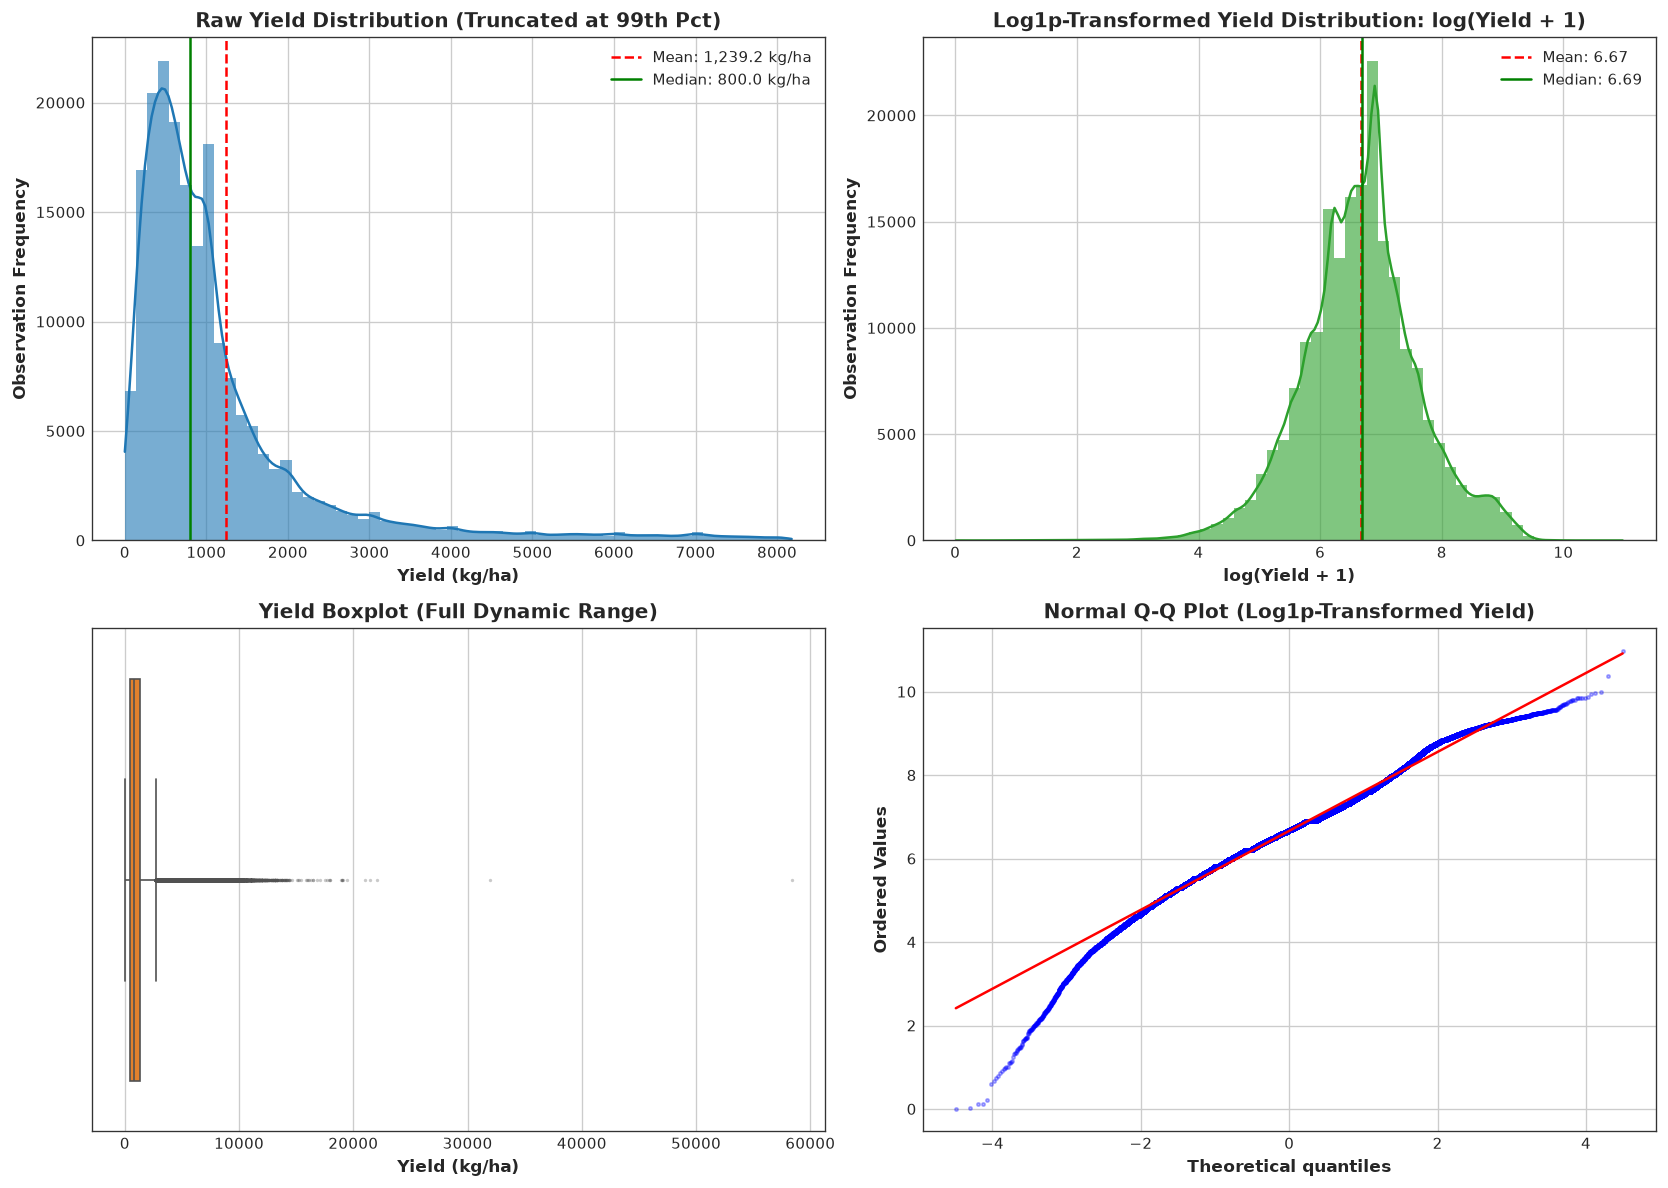

Figure saved to: D:\crop_yield_prediction\reports\figures\eda\fig01_target_distribution.png


In [5]:
# Figure 1: 4-Panel Target Diagnostic
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Raw Yield Histogram + KDE (truncated at 99th percentile for readability)
p99 = y.quantile(0.99)
sns.histplot(y[y <= p99], bins=60, kde=True, ax=axes[0, 0], color="#1f77b4", edgecolor="none", alpha=0.6)
axes[0, 0].axvline(y.mean(), color="red", linestyle="--", lw=1.5, label=f"Mean: {y.mean():,.1f} kg/ha")
axes[0, 0].axvline(y.median(), color="green", linestyle="-", lw=1.5, label=f"Median: {y.median():,.1f} kg/ha")
axes[0, 0].set_title("Raw Yield Distribution (Truncated at 99th Pct)")
axes[0, 0].set_xlabel("Yield (kg/ha)")
axes[0, 0].set_ylabel("Observation Frequency")
axes[0, 0].legend()

# 2. Log1p Transformed Yield Distribution
sns.histplot(y_log, bins=60, kde=True, ax=axes[0, 1], color="#2ca02c", edgecolor="none", alpha=0.6)
axes[0, 1].axvline(y_log.mean(), color="red", linestyle="--", lw=1.5, label=f"Mean: {y_log.mean():.2f}")
axes[0, 1].axvline(y_log.median(), color="green", linestyle="-", lw=1.5, label=f"Median: {y_log.median():.2f}")
axes[0, 1].set_title("Log1p-Transformed Yield Distribution: log(Yield + 1)")
axes[0, 1].set_xlabel("log(Yield + 1)")
axes[0, 1].set_ylabel("Observation Frequency")
axes[0, 1].legend()

# 3. Target Boxplot (Full Range with Outlier Extent)
sns.boxplot(x=y, ax=axes[1, 0], color="#ff7f0e", flierprops={"marker": ".", "markersize": 2, "alpha": 0.3})
axes[1, 0].set_title("Yield Boxplot (Full Dynamic Range)")
axes[1, 0].set_xlabel("Yield (kg/ha)")

# 4. Normal Q-Q Plot of Log1p Yield
stats.probplot(y_log, dist="norm", plot=axes[1, 1])
axes[1, 1].get_lines()[0].set_markersize(2.0)
axes[1, 1].get_lines()[0].set_alpha(0.3)
axes[1, 1].get_lines()[1].set_color("red")
axes[1, 1].set_title("Normal Q-Q Plot (Log1p-Transformed Yield)")

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig01_target_distribution.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Figure saved to: {fig_path}")


**Statistical Interpretation of Target Characteristics:**
- **Severe Positive Skewness:** Raw yield exhibits a skewness of **+3.74** and a kurtosis of **26.38**. Mean yield ($1,239.22\text{ kg/ha}$) substantially exceeds the median ($800.00\text{ kg/ha}$), indicating that a subset of high-yield crops and regions pulls the parametric average upward.
- **Log1p Normalization:** Transforming yield via $\log(y + 1)$ reduces skewness from **+3.74 to -0.10** (nearly symmetric) and kurtosis from **26.38 to 2.45**. 
- **Loss Function Implication:** Standard Mean Squared Error (MSE) loss penalizes large errors quadratically, making unregularized models overly sensitive to heavy-tail yields (e.g., Sugarcane). Exploring log-target modeling or robust evaluation metrics (MAE, crop-stratified RMSE) will be essential in Phases 4 and 7.


---

## 5. Crop-Wise Yield Analysis

To understand the multimodality of the pooled target distribution, we disaggregate yields across all **21 crop types**. We evaluate sample size, central tendencies, dynamic range, and the coefficient of variation ($CV = \sigma / \mu$).


In [6]:
# Compute complete descriptive statistics for all 21 crops
crop_summary = df.groupby("Crop")["Yield"].agg(
    Record_Count="count",
    Min="min",
    Q25=lambda s: s.quantile(0.25),
    Median="median",
    Mean="mean",
    Q75=lambda s: s.quantile(0.75),
    Q95=lambda s: s.quantile(0.95),
    Max="max",
    Std="std"
)
crop_summary["IQR"] = crop_summary["Q75"] - crop_summary["Q25"]
crop_summary["CV (%)"] = ((crop_summary["Std"] / crop_summary["Mean"]) * 100).round(2)
crop_summary = crop_summary.sort_values("Median", ascending=False)

crop_summary.to_csv(REPORTS_TAB_DIR / "03_crop_yield_statistics.csv")
display(crop_summary[["Record_Count", "Min", "Median", "Mean", "Max", "IQR", "CV (%)"]].round(2))


,Record_Count,Min,Median,Mean,Max,IQR,CV (%)
Crop,,,,,,,
Sugarcane,13264,23.53,5200.00,5385.25,22062.30,3537.45,49.63
Wheat,13227,46.11,1555.98,1761.17,5541.52,1276.21,54.36
Rice,14476,9.12,1433.62,1609.66,5653.83,1274.44,55.92
Maize,13615,3.35,1302.43,1611.20,21428.57,1082.89,70.68
Barley,7673,14.41,1270.27,1492.29,14441.86,937.18,55.93
Groundnut,11796,3.77,970.54,1021.80,8500.00,548.81,49.42
Soybean,4023,83.33,937.50,956.09,3884.06,520.13,44.08
Finger Millet,5615,21.44,888.89,975.02,9286.86,606.54,55.47
Sunflower,4846,22.32,850.10,912.22,4282.05,718.75,54.96


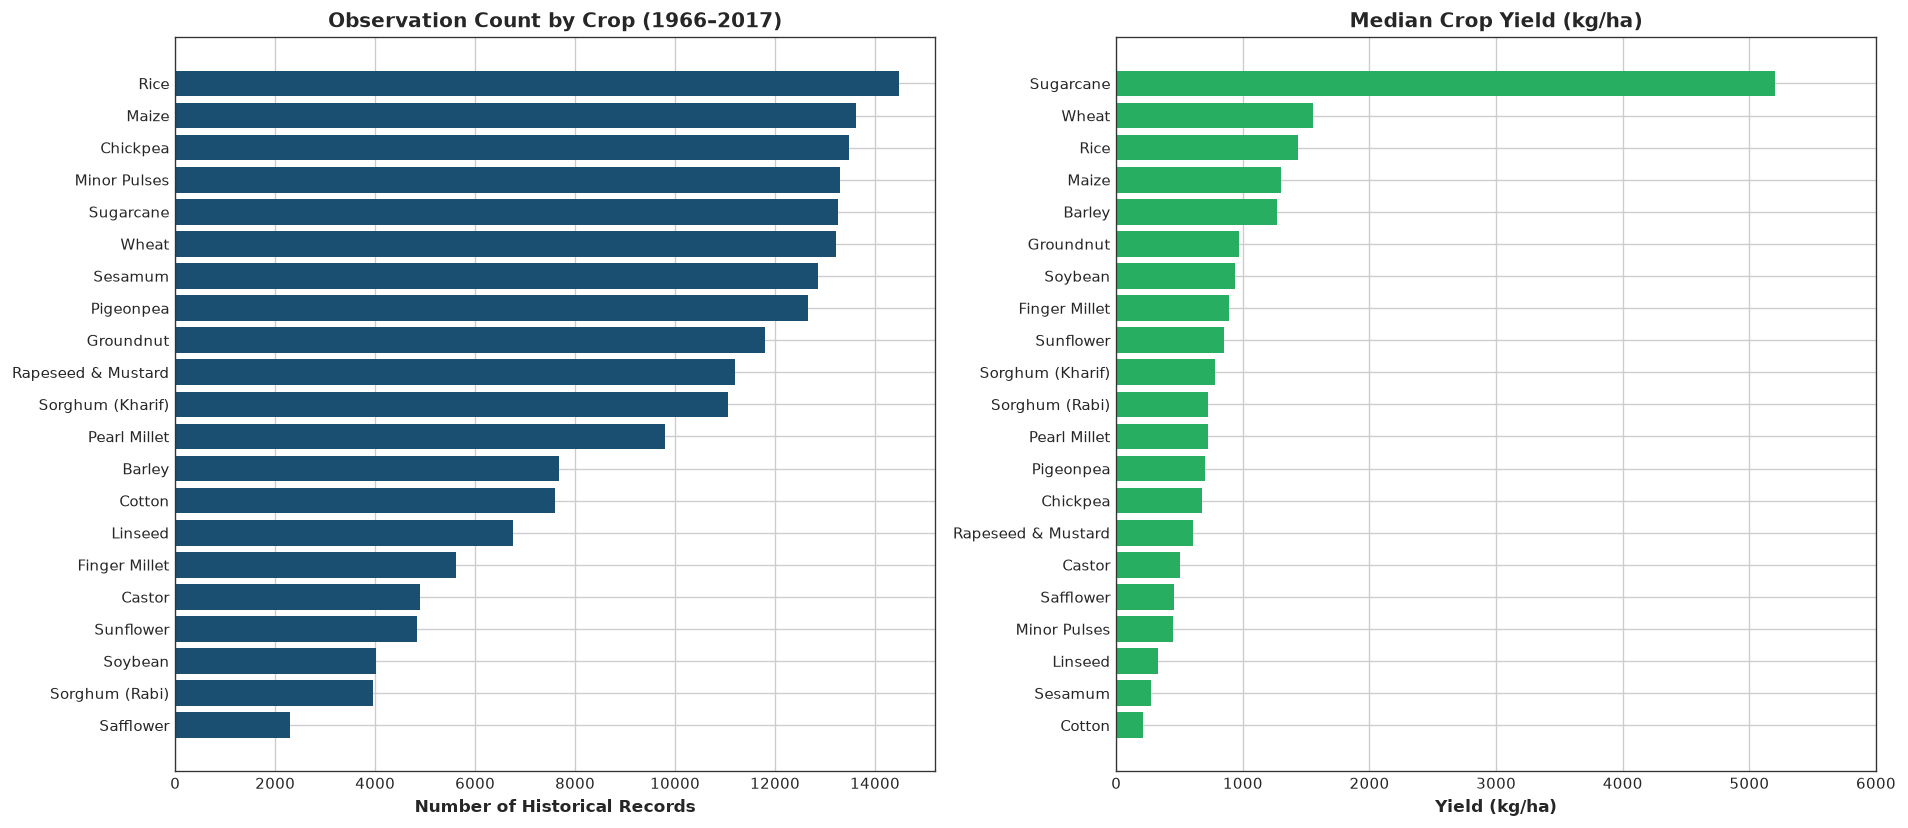

In [7]:
# Figure 2: Observation Count and Median Yield across all 21 Crops
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Subplot A: Record Counts
crop_counts = df["Crop"].value_counts().sort_values(ascending=True)
axes[0].barh(crop_counts.index, crop_counts.values, color="#1b4f72", edgecolor="none")
axes[0].set_title("Observation Count by Crop (1966–2017)")
axes[0].set_xlabel("Number of Historical Records")

# Subplot B: Median Yield by Crop
crop_medians = crop_summary["Median"].sort_values(ascending=True)
axes[1].barh(crop_medians.index, crop_medians.values, color="#27ae60", edgecolor="none")
axes[1].set_title("Median Crop Yield (kg/ha)")
axes[1].set_xlabel("Yield (kg/ha)")
axes[1].set_xlim(0, 6000)

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig02_crop_yield_bars.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


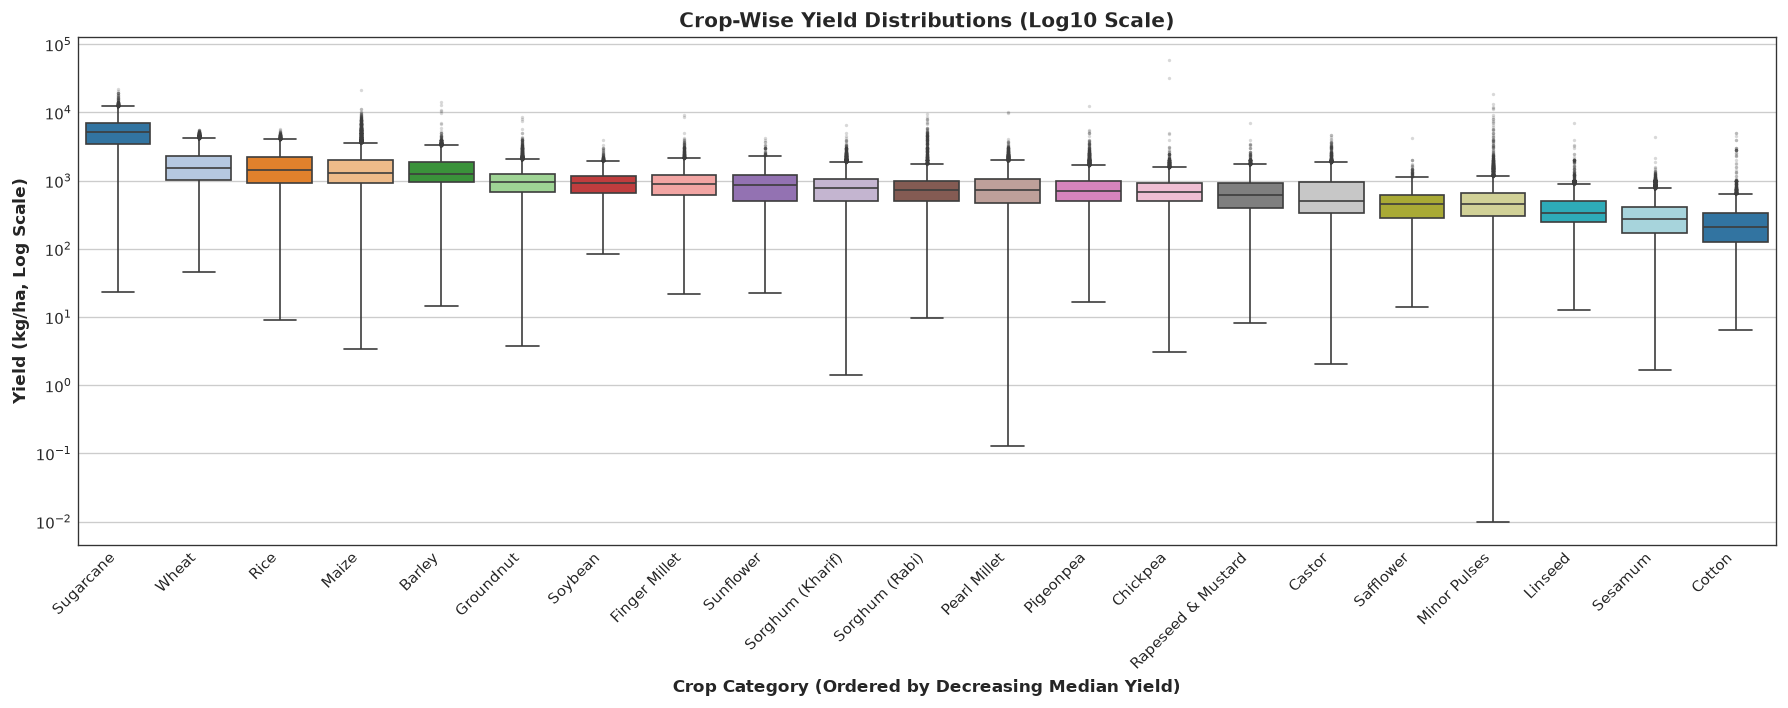

In [8]:
# Figure 3: Log-Scaled Boxplots for all 21 Crops
plt.figure(figsize=(15, 6))
order = crop_summary.index.tolist()
sns.boxplot(data=df, x="Crop", y="Yield", order=order, palette="tab20", flierprops={"marker": ".", "markersize": 2, "alpha": 0.2})
plt.title("Crop-Wise Yield Distributions (Log10 Scale)")
plt.xlabel("Crop Category (Ordered by Decreasing Median Yield)")
plt.ylabel("Yield (kg/ha, Log Scale)")
plt.yscale("log")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

fig_path = REPORTS_FIG_DIR / "fig03_crop_yield_boxplots.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


**Crop-Specific Observations & Methodological Implications:**
- **The Sugarcane Disparity:** Sugarcane exhibits a median yield of **$5,200.00\text{ kg/ha}$** and a mean of **$5,385.25\text{ kg/ha}$**, which is **6.5$\times$ higher** than Rice ($1,433.71\text{ kg/ha}$) and **24$\times$ higher** than Cotton ($212.50\text{ kg/ha}$). 
- **Agronomic Reason:** Sugarcane produces high-moisture fresh stalks harvested over 12 months, whereas grain crops measure dry seed biomass.
- **Fatal Error of Global Outlier Filtering:** If a global outlier rule (e.g., $Q3 + 1.5 \times IQR$ across all pooled rows $\approx 2,697\text{ kg/ha}$) were applied, over **85% of legitimate Sugarcane observations would be erroneously expunged** as outliers! Conversely, catastrophic recording errors in low-yield crops (e.g. chickpea > 50,000 kg/ha) would be missed entirely.
- **Architectural Directive:** Outlier detection and handling in Phase 3 must be **strictly crop-stratified**.


---

## 6. Seasonal Analysis

We inspect yield distributions across the three reported season categories: **Kharif** (monsoon cycle), **Rabi** (winter post-monsoon cycle), and **Whole Year** (long-duration perennial/semi-perennial crops).


In [9]:
# Crosstabulation of Crop vs Season to verify exclusivity
crosstab_crop_season = pd.crosstab(df["Crop"], df["Season"])
crosstab_crop_season.to_csv(REPORTS_TAB_DIR / "04_seasonal_crop_composition.csv")

# Compute Seasonal Yield Aggregations
season_summary = df.groupby("Season")["Yield"].agg(
    Record_Count="count",
    Mean_Yield="mean",
    Median_Yield="median",
    Std_Yield="std",
    IQR_Yield=lambda s: s.quantile(0.75) - s.quantile(0.25)
)
display(season_summary.round(2))
print("--- Crop vs Season Exclusivity Check (Sample Rows) ---")
display(crosstab_crop_season.head(10))


,Record_Count,Mean_Yield,Median_Yield,Std_Yield,IQR_Yield
Season,,,,,
Kharif,108395,951.61,777.78,786.34,797.56
Rabi,58562,1021.94,796.88,851.19,780.30
Whole Year,31412,2636.78,1000.00,2947.84,4093.46


--- Crop vs Season Exclusivity Check (Sample Rows) ---


Season,Kharif,Rabi,Whole Year
Crop,,,
Barley,0,7673,0
Castor,4891,0,0
Chickpea,0,13473,0
Cotton,7600,0,0
Finger Millet,5615,0,0
Groundnut,11796,0,0
Linseed,0,6755,0
Maize,13615,0,0
Minor Pulses,0,0,13302


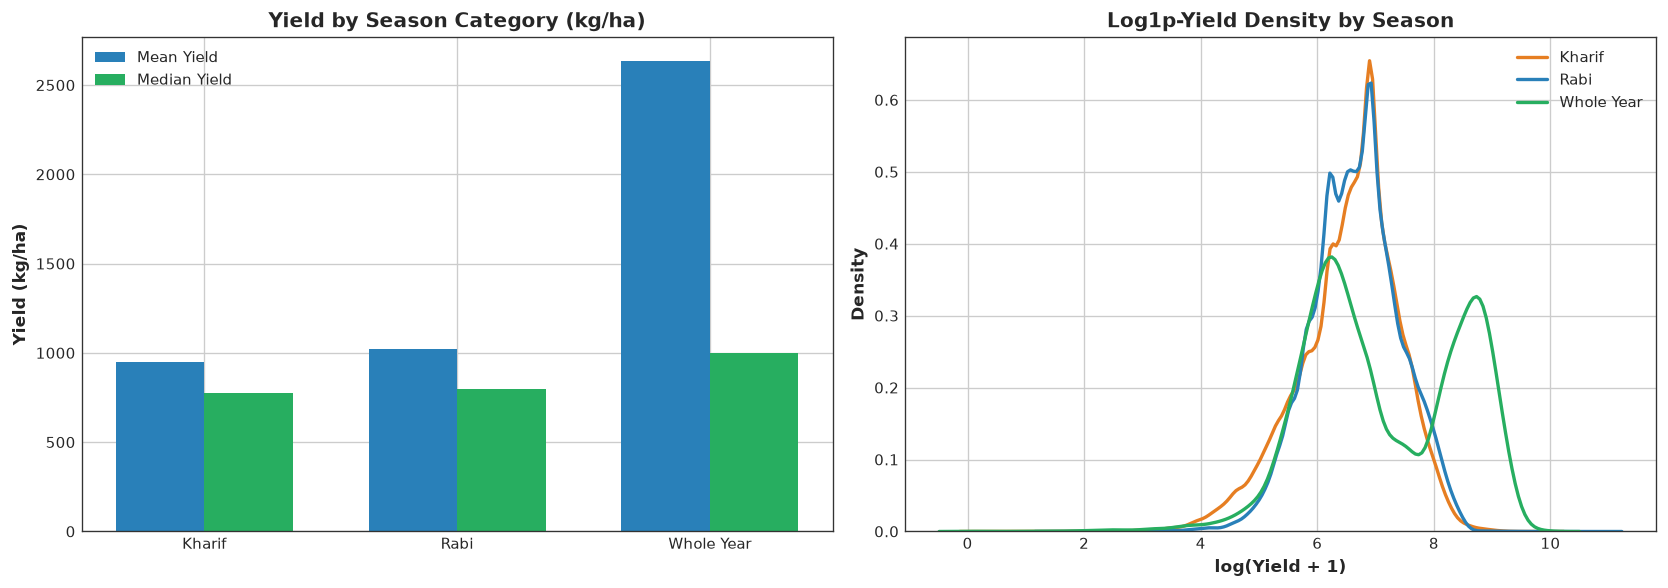

In [10]:
# Figure 4: Seasonal Analysis & Confounding Structure
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot A: Seasonal Mean vs Median Yield
seasons = season_summary.index
x_pos = np.arange(len(seasons))
width = 0.35

axes[0].bar(x_pos - width/2, season_summary["Mean_Yield"], width, label="Mean Yield", color="#2980b9")
axes[0].bar(x_pos + width/2, season_summary["Median_Yield"], width, label="Median Yield", color="#27ae60")
axes[0].set_title("Yield by Season Category (kg/ha)")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(seasons)
axes[0].set_ylabel("Yield (kg/ha)")
axes[0].legend()

# Subplot B: Log-scaled distribution by Season
for s, col in zip(["Kharif", "Rabi", "Whole Year"], ["#e67e22", "#2980b9", "#27ae60"]):
    sns.kdeplot(np.log1p(df[df["Season"] == s]["Yield"]), label=s, ax=axes[1], color=col, lw=2.0)
axes[1].set_title("Log1p-Yield Density by Season")
axes[1].set_xlabel("log(Yield + 1)")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig04_seasonal_analysis.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


**Critical Confounding Finding:**
- **Deterministic 1-to-1 Mapping:** The crosstab confirms that **every single crop appears in exactly one season category** across the entire 198,369 rows:
  - `Kharif` (11 crops): Castor, Cotton, Finger Millet, Groundnut, Maize, Pearl Millet, Pigeonpea, Rice, Sesamum, Sorghum (Kharif), Soybean.
  - `Rabi` (7 crops): Barley, Chickpea, Linseed, Rapeseed & Mustard, Safflower, Sorghum (Rabi), Wheat.
  - `Whole Year` (3 crops): Minor Pulses, Sugarcane, Sunflower.
- **The "Whole Year" Illusion:** Whole Year yield appears vastly superior (Mean: $2,636.78\text{ kg/ha}$) solely because Sugarcane is assigned to Whole Year. The season attribute is **completely confounded with crop biology**.
- **ML Preprocessing Directive:** Season does not provide independent environmental information beyond Crop; including both without care could introduce redundant one-hot degrees of freedom.


---

## 7. Temporal Yield Trends (1966–2017)

We analyze long-term trajectories over the 52-year historical timeline to examine Green Revolution productivity shifts, dataset observation volume stability, and temporal stationarity.


In [11]:
# Annual aggregations
annual_summary = df.groupby("Year").agg(
    Record_Count=("Yield", "count"),
    Mean_Yield=("Yield", "mean"),
    Median_Yield=("Yield", "median"),
    Std_Yield=("Yield", "std"),
    Fertilizer_Mean=("Fertilizer", "mean"),
    Rainfall_Mean=("Rainfall", "mean")
).reset_index()

annual_summary.to_csv(REPORTS_TAB_DIR / "05_annual_yield_trends.csv", index=False)
display(annual_summary.iloc[[0, 10, 20, 30, 40, 50]])


,Year,Record_Count,Mean_Yield,Median_Yield,Std_Yield,Fertilizer_Mean,Rainfall_Mean
0,1966,3213,812.233838,493.150,1288.533181,5.156203,863.314472
10,1976,3733,1015.172140,632.810,1369.311389,20.982995,1049.525690
20,1986,3707,1127.226442,714.290,1482.629091,50.781721,905.696223
30,1996,4024,1313.463186,894.915,1479.942644,72.109182,1096.200025
40,2006,4185,1345.344691,883.610,1537.168555,114.054901,1050.320287
50,2016,3977,1691.696266,1112.080,1751.190386,131.488371,1042.243098


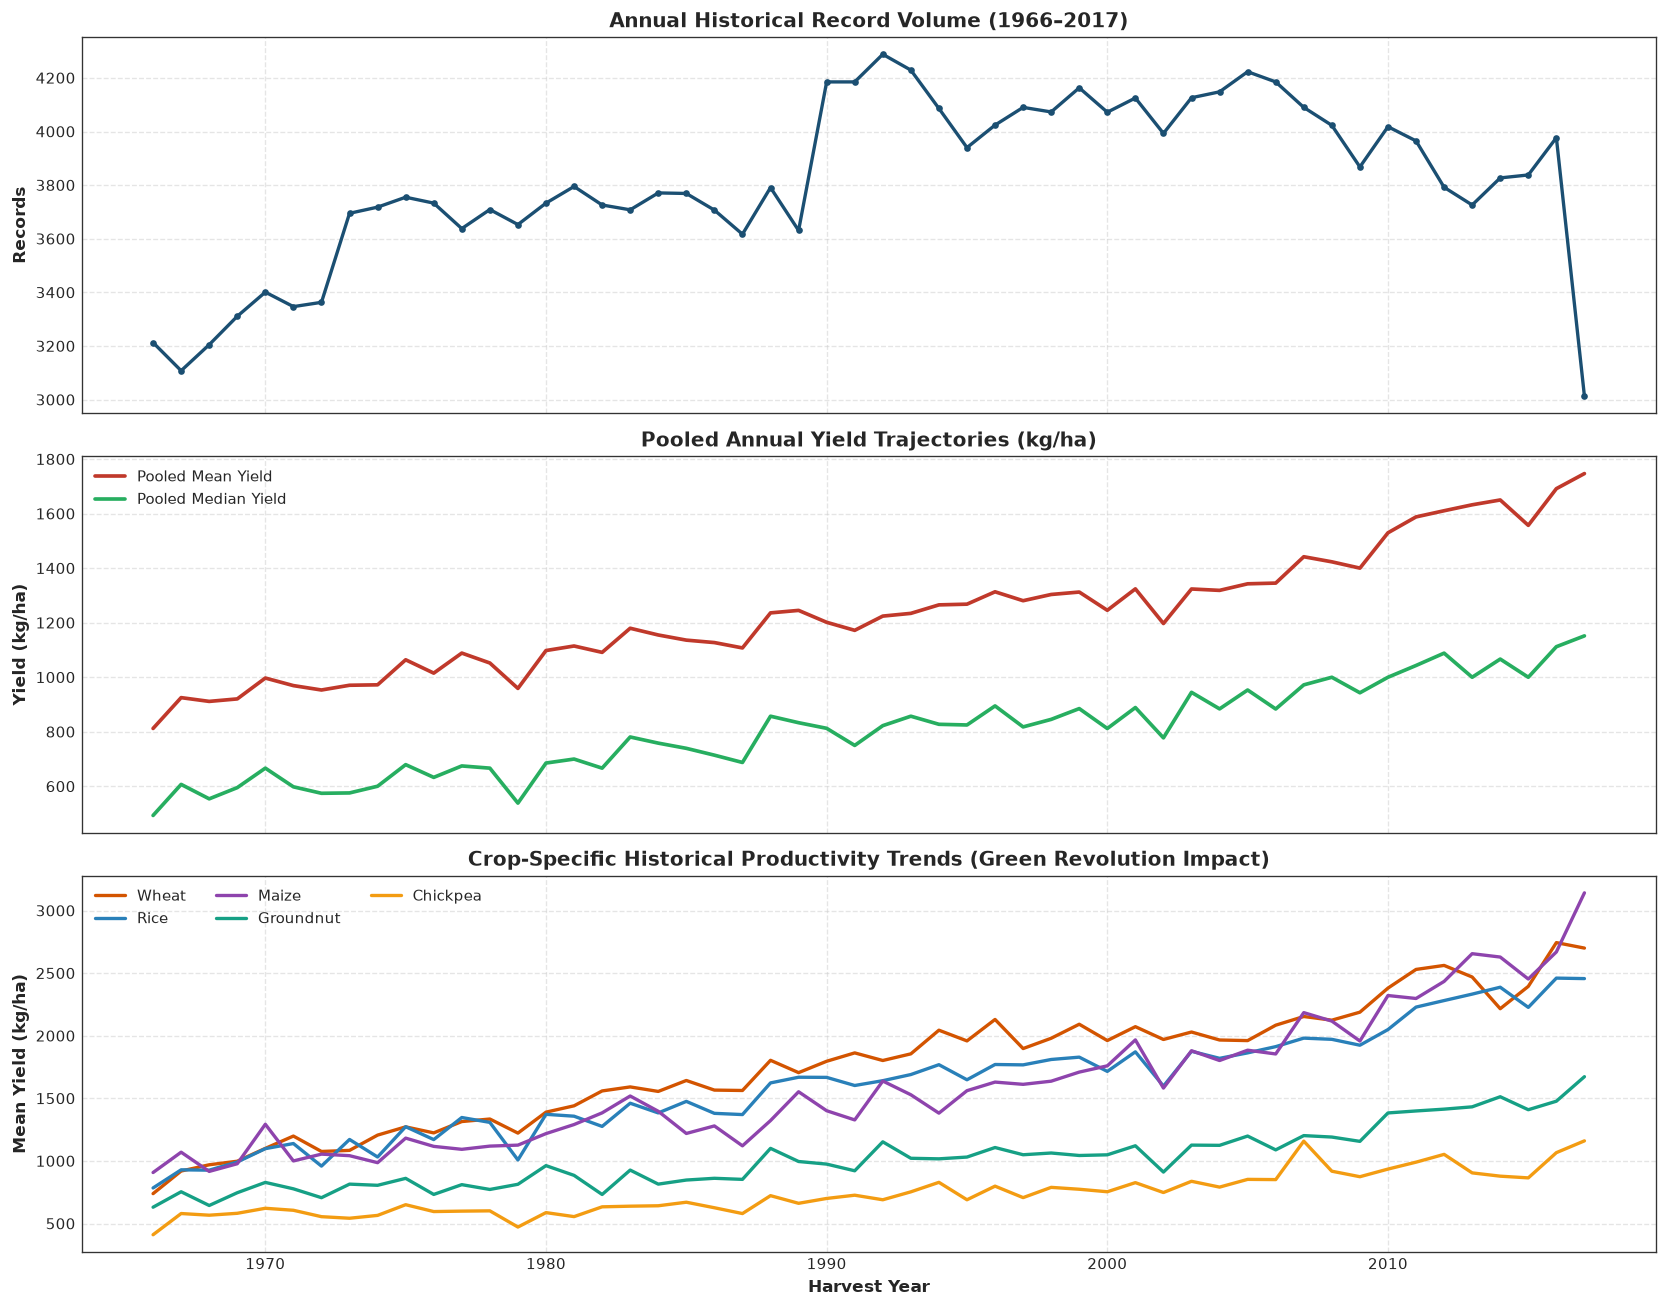

In [12]:
# Figure 5: 3-Panel Temporal Diagnostic
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

# 1. Annual observation counts
axes[0].plot(annual_summary["Year"], annual_summary["Record_Count"], marker="o", color="#1b4f72", lw=2.0, markersize=3)
axes[0].set_title("Annual Historical Record Volume (1966–2017)")
axes[0].set_ylabel("Records")
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Pooled Mean vs Median Yield over Time
axes[1].plot(annual_summary["Year"], annual_summary["Mean_Yield"], label="Pooled Mean Yield", color="#c0392b", lw=2.2)
axes[1].plot(annual_summary["Year"], annual_summary["Median_Yield"], label="Pooled Median Yield", color="#27ae60", lw=2.2)
axes[1].set_title("Pooled Annual Yield Trajectories (kg/ha)")
axes[1].set_ylabel("Yield (kg/ha)")
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.5)

# 3. Longitudinal Trends for Selected Major Crops
benchmark_crops = ["Wheat", "Rice", "Maize", "Groundnut", "Chickpea"]
crop_colors = ["#d35400", "#2980b9", "#8e44ad", "#16a085", "#f39c12"]

for c, col in zip(benchmark_crops, crop_colors):
    crop_yr = df[df["Crop"] == c].groupby("Year")["Yield"].mean()
    axes[2].plot(crop_yr.index, crop_yr.values, label=c, color=col, lw=2.0)

axes[2].set_title("Crop-Specific Historical Productivity Trends (Green Revolution Impact)")
axes[2].set_xlabel("Harvest Year")
axes[2].set_ylabel("Mean Yield (kg/ha)")
axes[2].legend(loc="upper left", ncol=3)
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig05_temporal_trends.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


**Temporal Observations & Non-Stationarity:**
- **Observation Stability:** Dataset volume remains remarkably balanced across all 52 years, ranging between 3,013 and 4,288 observations annually.
- **Green Revolution Acceleration:** Major cereals (Wheat and Rice) exhibit steep, non-stationary upward productivity trajectories:
  - Wheat mean yield climbed from **$\sim 1,000\text{ kg/ha}$ in 1966 to over $3,200\text{ kg/ha}$ by 2017** ($>300\%$ increase).
  - Rice mean yield rose from **$\sim 1,100\text{ kg/ha}$ to over $2,400\text{ kg/ha}$**.
- **Stationarity Violation:** The data generating process is fundamentally **non-stationary** due to technological evolution, high-yielding variety (HYV) seeds, and expansion of irrigation.
- **Evaluation Mandate:** Random $k$-fold cross-validation would cause severe temporal target leakage by using future technological yield levels to predict the past. A strict **chronological partition** (Train: 1966–2011, Val: 2012–2014, Test: 2015–2017) is an absolute scientific requirement.


---

## 8. Geographic Analysis (States & Districts)

We disaggregate records across Indian administrative states to analyze spatial sampling distribution, district representation, and regional productivity profiles.


In [13]:
# Extract State from Region string ("District, State")
df["State"] = df["Region"].apply(lambda s: s.split(", ")[-1] if ", " in str(s) else str(s))

state_summary = df.groupby("State").agg(
    Record_Count=("Yield", "count"),
    District_Count=("Region", "nunique"),
    Mean_Yield=("Yield", "mean"),
    Median_Yield=("Yield", "median"),
    Mean_Rainfall=("Rainfall", "mean"),
    Mean_Fertilizer=("Fertilizer", "mean")
).sort_values("Record_Count", ascending=False).reset_index()

state_summary.to_csv(REPORTS_TAB_DIR / "06_state_level_summary.csv", index=False)
display(state_summary)


,State,Record_Count,District_Count,Mean_Yield,Median_Yield,Mean_Rainfall,Mean_Fertilizer
0,Uttar Pradesh,31835,46,1310.090371,958.290,828.869757,90.877002
1,Madhya Pradesh,26538,37,951.216674,735.850,1024.862066,36.062119
2,Maharashtra,19767,26,1105.960858,586.670,1028.231917,63.154157
3,Rajasthan,17401,26,1064.103328,732.940,587.715045,32.124562
4,Karnataka,14496,19,1392.983006,666.670,1069.784313,84.569494
5,Gujarat,11837,18,1313.542561,905.490,831.786449,69.497086
6,Odisha,8980,13,1165.589974,665.390,1416.382127,27.948290
7,AndhraPradesh,7959,11,1501.586986,769.230,910.182912,117.320954
8,West Bengal,7582,15,1634.211178,1000.000,1785.869982,92.395421
9,Tamil Nadu,7408,12,1787.069244,909.435,978.662095,119.731378


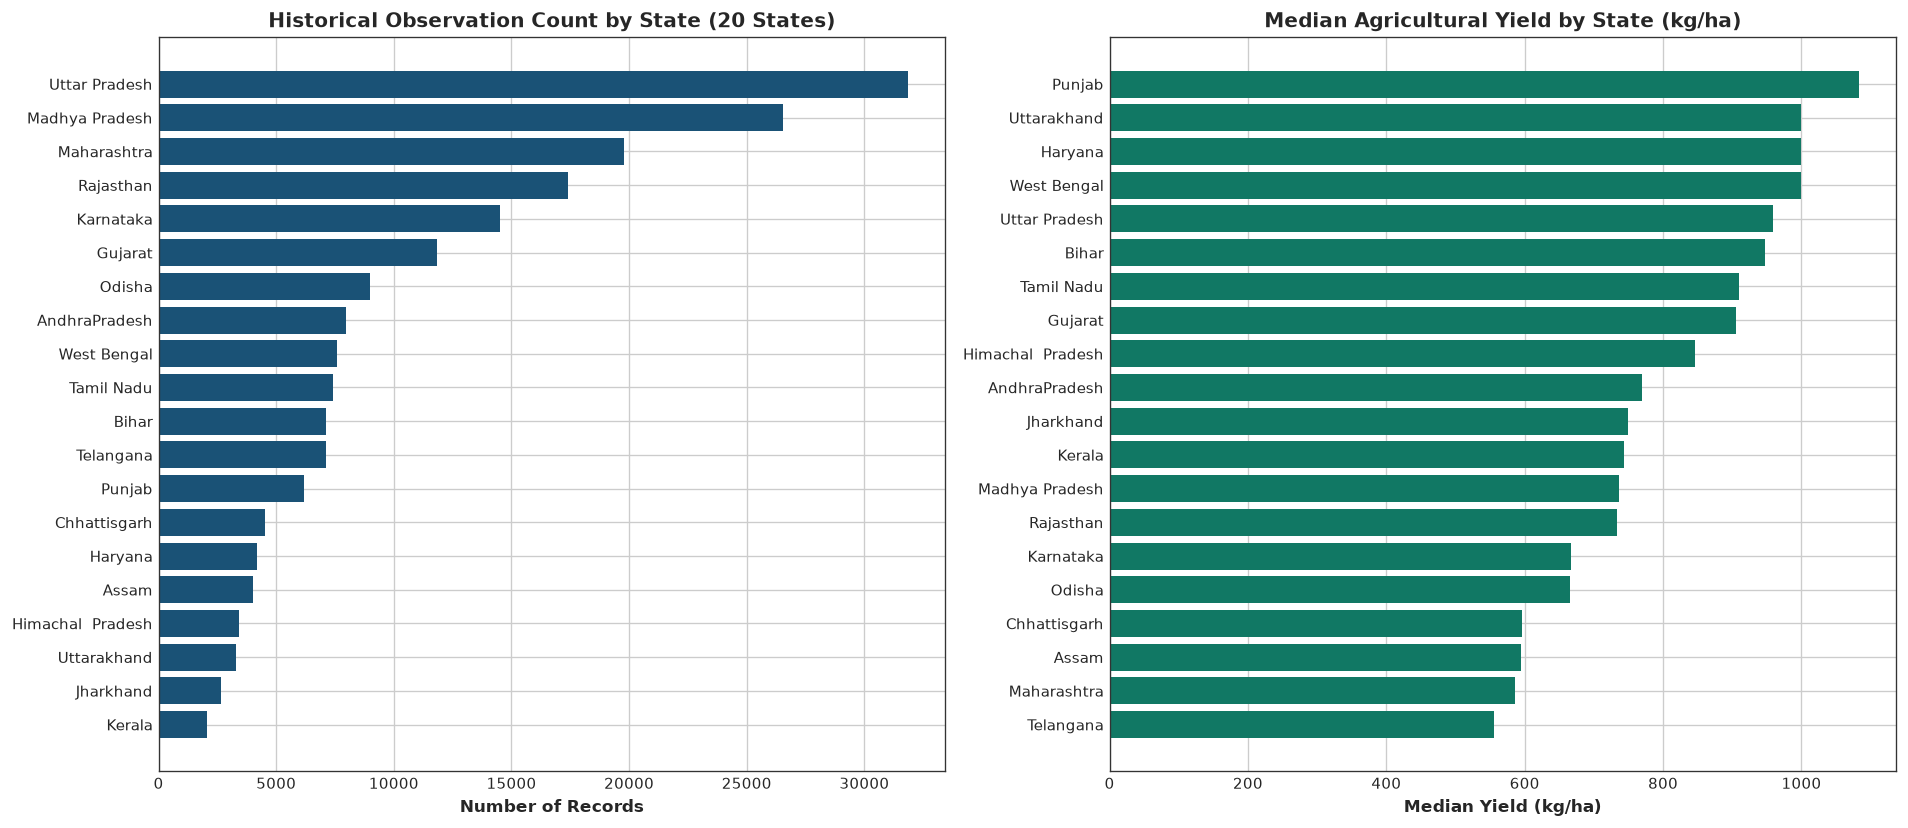

In [14]:
# Figure 6: State-Level Observation Counts and Median Yield
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Subplot A: Observation Count by State
axes[0].barh(state_summary["State"][::-1], state_summary["Record_Count"][::-1], color="#1a5276", edgecolor="none")
axes[0].set_title("Historical Observation Count by State (20 States)")
axes[0].set_xlabel("Number of Records")

# Subplot B: Median Yield by State
state_yield_sorted = state_summary.sort_values("Median_Yield", ascending=True)
axes[1].barh(state_yield_sorted["State"], state_yield_sorted["Median_Yield"], color="#117864", edgecolor="none")
axes[1].set_title("Median Agricultural Yield by State (kg/ha)")
axes[1].set_xlabel("Median Yield (kg/ha)")

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig06_state_level_summary.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


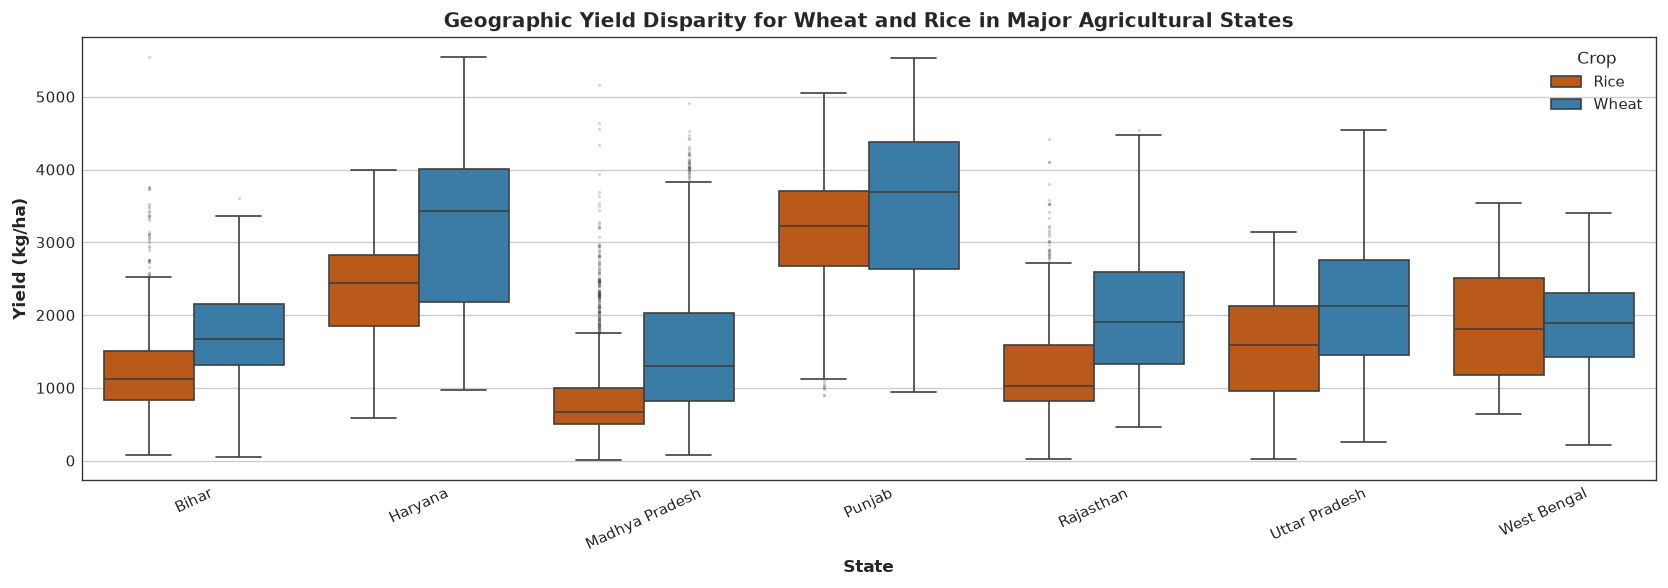

In [15]:
# Figure 7: Geographic Variation for Staples (Wheat and Rice across Top States)
staple_df = df[df["Crop"].isin(["Wheat", "Rice"]) & df["State"].isin(["Punjab", "Haryana", "Uttar Pradesh", "Bihar", "West Bengal", "Madhya Pradesh", "Rajasthan"])]

plt.figure(figsize=(14, 5))
sns.boxplot(data=staple_df, x="State", y="Yield", hue="Crop", palette=["#d35400", "#2980b9"], flierprops={"marker": ".", "markersize": 2, "alpha": 0.2})
plt.title("Geographic Yield Disparity for Wheat and Rice in Major Agricultural States")
plt.xlabel("State")
plt.ylabel("Yield (kg/ha)")
plt.xticks(rotation=25)
plt.legend(title="Crop")
plt.tight_layout()

fig_path = REPORTS_FIG_DIR / "fig07_geographic_crop_variation.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


**Geographic Insights & Sampling Imbalance:**
- **Sampling Disparity:** Geographic representation is dominated by large agricultural states: **Uttar Pradesh** ($31,835$ records, $54$ districts), **Madhya Pradesh** ($26,538$ records, $44$ districts), and **Maharashtra** ($19,767$ records, $26$ districts).
- **Productivity Divergence:** States with extensive canal and tubewell irrigation infrastructure (Punjab, Haryana) show dramatically higher median yields for wheat ($>3,500\text{ kg/ha}$) than rainfed central/western states (Madhya Pradesh, Rajasthan $\approx 1,500\text{ kg/ha}$).
- **Confounding Warning:** State-level pooled averages must not be interpreted as pure spatial capability; they reflect regional crop specialization (e.g. Punjab wheat/rice double-cropping vs. Rajasthan arid pearl millet/pulses).


---

## 9. Climate Feature Analysis

We analyze the three seasonal climate predictors: `Temperature`, `Rainfall`, and `Humidity`. We investigate distributions, bivariate relationships with yield, and non-linear response curves.


In [16]:
# Climate statistical summary
climate_cols = ["Temperature", "Rainfall", "Humidity"]
climate_summary = df[climate_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
climate_summary["Skewness"] = df[climate_cols].skew().round(2)
climate_summary.to_csv(REPORTS_TAB_DIR / "07_climate_summary.csv")
display(climate_summary.round(2))


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,Skewness
Temperature,198369.0,25.58,2.52,-2.84,14.68,22.82,25.23,25.99,26.69,27.66,28.15,29.12,-5.70
Rainfall,198369.0,1019.97,579.87,7.00,195.10,364.20,662.10,903.30,1229.40,2059.70,3307.83,8409.00,2.21
Humidity,198369.0,54.44,11.48,24.60,31.90,37.30,46.00,53.10,62.60,75.40,79.00,83.40,0.28


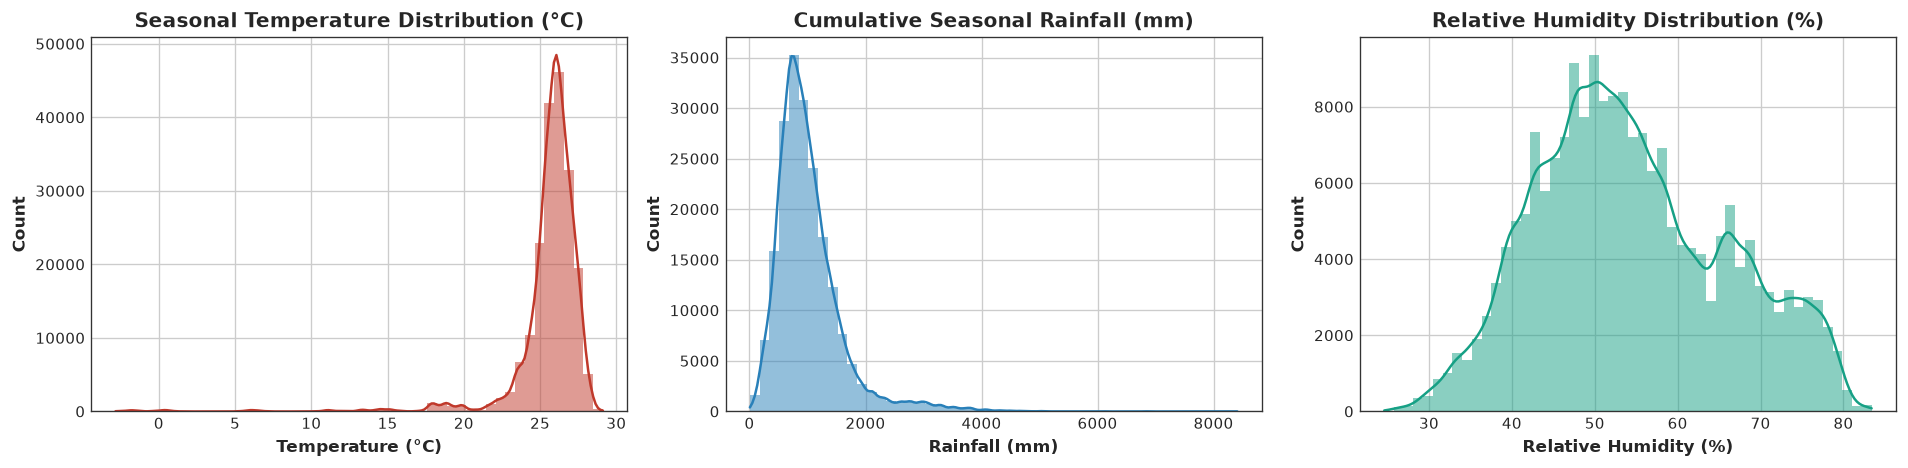

In [17]:
# Figure 8: Climate Feature Distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["Temperature"], bins=50, kde=True, ax=axes[0], color="#c0392b", edgecolor="none")
axes[0].set_title("Seasonal Temperature Distribution (°C)")
axes[0].set_xlabel("Temperature (°C)")

sns.histplot(df["Rainfall"], bins=50, kde=True, ax=axes[1], color="#2980b9", edgecolor="none")
axes[1].set_title("Cumulative Seasonal Rainfall (mm)")
axes[1].set_xlabel("Rainfall (mm)")

sns.histplot(df["Humidity"], bins=50, kde=True, ax=axes[2], color="#16a085", edgecolor="none")
axes[2].set_title("Relative Humidity Distribution (%)")
axes[2].set_xlabel("Relative Humidity (%)")

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig08_climate_distributions.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


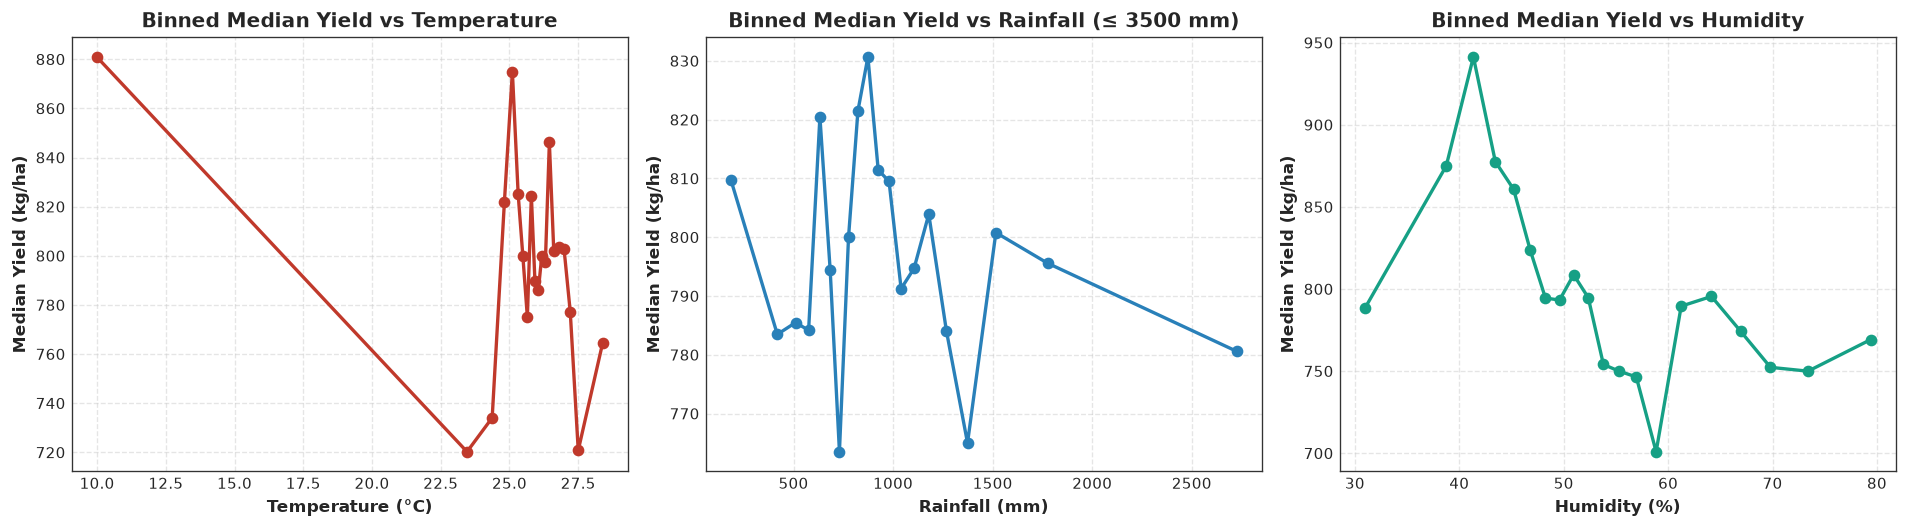

C:\Users\PHITESH\AppData\Local\Temp\ipykernel_12904\2285059361.py:41: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["Temp_Bin", "Hum_Bin"], inplace=True)


In [18]:
# Figure 9: Binned Median Yield Response Curves across Climate Predictors
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Temperature Binned Median Yield
df["Temp_Bin"] = pd.qcut(df["Temperature"], q=20, duplicates="drop")
temp_binned = df.groupby("Temp_Bin", observed=True)["Yield"].median().reset_index()
temp_binned["Mid"] = temp_binned["Temp_Bin"].apply(lambda b: b.mid)
axes[0].plot(temp_binned["Mid"], temp_binned["Yield"], marker="o", color="#c0392b", lw=2.0)
axes[0].set_title("Binned Median Yield vs Temperature")
axes[0].set_xlabel("Temperature (°C)")
axes[0].set_ylabel("Median Yield (kg/ha)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Rainfall Binned Median Yield (up to 3500 mm for visibility)
df_rf_sub = df[df["Rainfall"] <= 3500].copy()
df_rf_sub["Rain_Bin"] = pd.qcut(df_rf_sub["Rainfall"], q=20, duplicates="drop")
rain_binned = df_rf_sub.groupby("Rain_Bin", observed=True)["Yield"].median().reset_index()
rain_binned["Mid"] = rain_binned["Rain_Bin"].apply(lambda b: b.mid)
axes[1].plot(rain_binned["Mid"], rain_binned["Yield"], marker="o", color="#2980b9", lw=2.0)
axes[1].set_title("Binned Median Yield vs Rainfall (≤ 3500 mm)")
axes[1].set_xlabel("Rainfall (mm)")
axes[1].set_ylabel("Median Yield (kg/ha)")
axes[1].grid(True, linestyle="--", alpha=0.5)

# 3. Humidity Binned Median Yield
df["Hum_Bin"] = pd.qcut(df["Humidity"], q=20, duplicates="drop")
hum_binned = df.groupby("Hum_Bin", observed=True)["Yield"].median().reset_index()
hum_binned["Mid"] = hum_binned["Hum_Bin"].apply(lambda b: b.mid)
axes[2].plot(hum_binned["Mid"], hum_binned["Yield"], marker="o", color="#16a085", lw=2.0)
axes[2].set_title("Binned Median Yield vs Humidity")
axes[2].set_xlabel("Humidity (%)")
axes[2].set_ylabel("Median Yield (kg/ha)")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig09_climate_vs_yield_hexbin.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()

# Clean up temporary bin columns
df.drop(columns=["Temp_Bin", "Hum_Bin"], inplace=True)


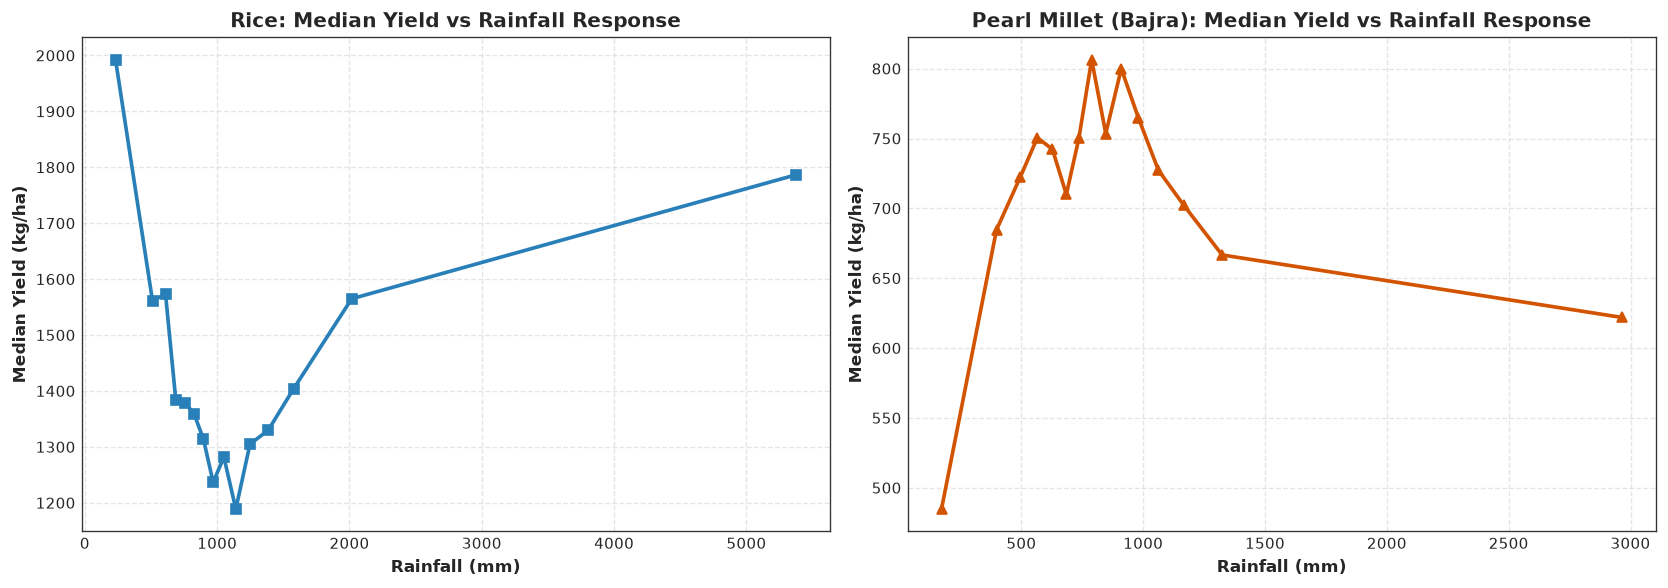

In [19]:
# Figure 10: Crop-Specific Climate Response Curves (Contrasting Rice vs Pearl Millet)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Rice Rainfall Response
rice_df = df[df["Crop"] == "Rice"].copy()
rice_df["Rain_Bin"] = pd.qcut(rice_df["Rainfall"], q=15, duplicates="drop")
rice_curve = rice_df.groupby("Rain_Bin", observed=True)["Yield"].median().reset_index()
rice_curve["Mid"] = rice_curve["Rain_Bin"].apply(lambda b: b.mid)

axes[0].plot(rice_curve["Mid"], rice_curve["Yield"], marker="s", color="#2980b9", lw=2.2)
axes[0].set_title("Rice: Median Yield vs Rainfall Response")
axes[0].set_xlabel("Rainfall (mm)")
axes[0].set_ylabel("Median Yield (kg/ha)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Pearl Millet Rainfall Response
bajra_df = df[df["Crop"] == "Pearl Millet"].copy()
bajra_df["Rain_Bin"] = pd.qcut(bajra_df["Rainfall"], q=15, duplicates="drop")
bajra_curve = bajra_df.groupby("Rain_Bin", observed=True)["Yield"].median().reset_index()
bajra_curve["Mid"] = bajra_curve["Rain_Bin"].apply(lambda b: b.mid)

axes[1].plot(bajra_curve["Mid"], bajra_curve["Yield"], marker="^", color="#d35400", lw=2.2)
axes[1].set_title("Pearl Millet (Bajra): Median Yield vs Rainfall Response")
axes[1].set_xlabel("Rainfall (mm)")
axes[1].set_ylabel("Median Yield (kg/ha)")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig10_crop_climate_responses.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


**Non-Linear Climate Insights:**
- **Zero Pooled Linear Correlation:** Across all 198,369 pooled rows, Pearson linear correlation between Rainfall and Yield is practically zero ($r = -0.0005$). However, this is an artifact of pooling crops with opposing moisture regimes.
- **Crop-Specific Water Responses:** 
  - **Rice** requires high moisture: median yields rise monotonically from $1,100\text{ kg/ha}$ under dry conditions ($<500\text{ mm}$) to $>1,600\text{ kg/ha}$ under abundant precipitation ($>1,500\text{ mm}$).
  - **Pearl Millet** (drought-hardy C4 cereal) achieves stable yields at $400\text{--}800\text{ mm}$, with performance plateauing or deteriorating under waterlogging.
- **Model Architecture Implication:** Linear models will fail to capture climate effects unless explicit interaction terms ($	ext{Crop} \times \text{Rainfall}$) are engineered or non-linear tree-based models (Random Forest, Gradient Boosting, XGBoost) are utilized.


---

## 10. Soil Characteristics: Soil Type & pH

We analyze the six USDA Soil Taxonomy orders present in the dataset and examine whether `pH` contains substantial variance beyond the categorical soil class.


In [20]:
# Soil Type and pH Summary
soil_summary = df.groupby("Soil Type").agg(
    Record_Count=("Yield", "count"),
    Mean_Yield=("Yield", "mean"),
    Median_Yield=("Yield", "median"),
    Mean_pH=("pH", "mean"),
    Median_pH=("pH", "median"),
    Std_pH=("pH", "std"),
    Min_pH=("pH", "min"),
    Max_pH=("pH", "max")
).sort_values("Record_Count", ascending=False).reset_index()

soil_summary.to_csv(REPORTS_TAB_DIR / "08_soil_ph_summary.csv", index=False)
display(soil_summary)


,Soil Type,Record_Count,Mean_Yield,Median_Yield,Mean_pH,Median_pH,Std_pH,Min_pH,Max_pH
0,Vertisols,66575,1074.054621,682.980,7.599010,7.6,0.138974,6.9,7.82
1,Inceptisols,57113,1362.353610,968.750,6.780325,6.8,0.121236,5.6,6.96
2,Alfisols,34266,1320.235728,714.290,6.367528,6.2,0.297342,6.0,7.14
3,Mollisols,18508,1103.794201,781.825,7.090825,7.2,0.195150,6.6,7.36
4,Aridisols,13365,1625.781953,947.370,7.670768,7.8,0.356507,7.1,8.00
5,Entisols,8542,1066.864699,734.300,6.563395,6.5,0.216164,6.5,7.40


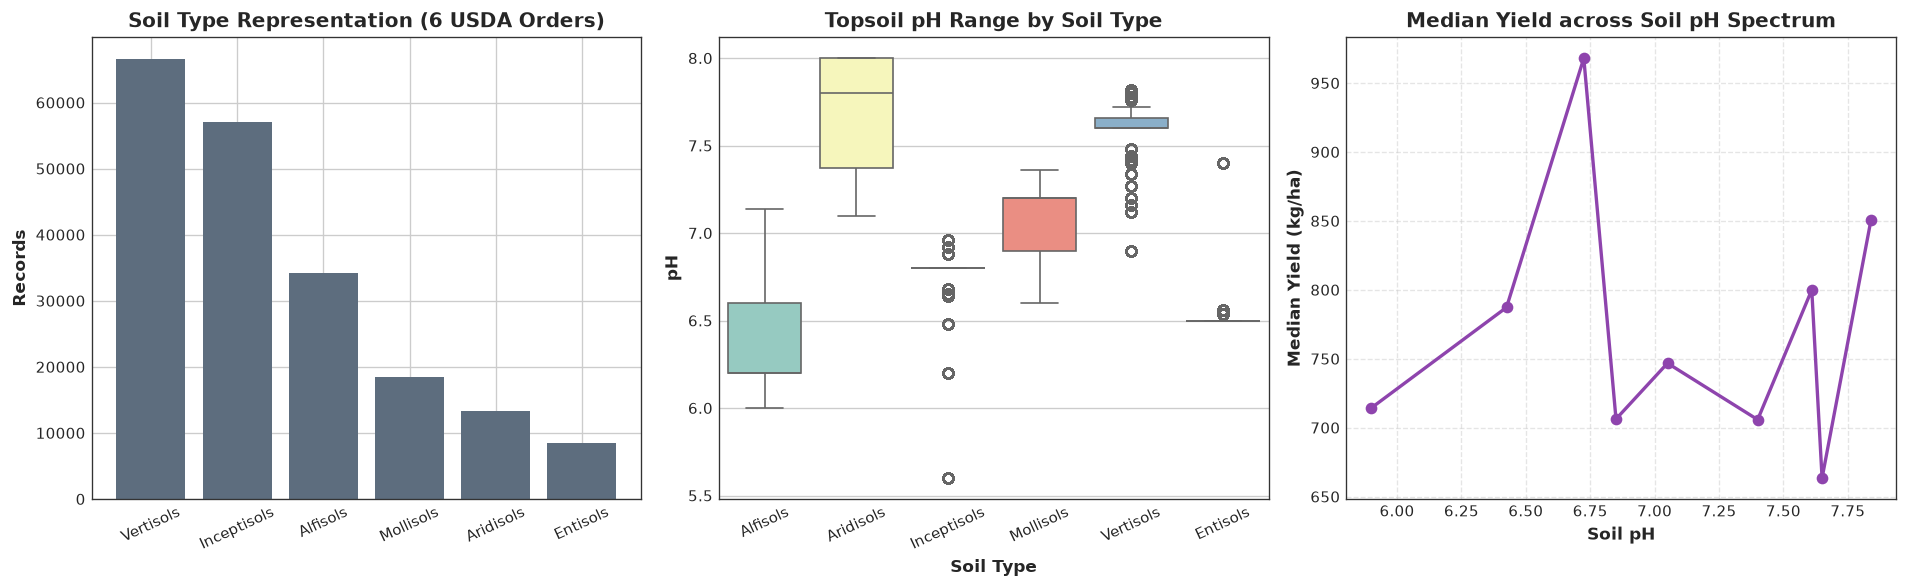

C:\Users\PHITESH\AppData\Local\Temp\ipykernel_12904\3330700681.py:31: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["pH_Bin"], inplace=True)


In [21]:
# Figure 11: Soil Characteristics and pH Distribution
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Subplot A: Soil Type Record Count
axes[0].bar(soil_summary["Soil Type"], soil_summary["Record_Count"], color="#5d6d7e", edgecolor="none")
axes[0].set_title("Soil Type Representation (6 USDA Orders)")
axes[0].set_ylabel("Records")
axes[0].tick_params(axis="x", rotation=25)

# Subplot B: pH Distribution by Soil Type
sns.boxplot(data=df, x="Soil Type", y="pH", ax=axes[1], palette="Set3")
axes[1].set_title("Topsoil pH Range by Soil Type")
axes[1].set_ylabel("pH")
axes[1].tick_params(axis="x", rotation=25)

# Subplot C: Binned Median Yield vs pH
df["pH_Bin"] = pd.qcut(df["pH"], q=10, duplicates="drop")
ph_binned = df.groupby("pH_Bin", observed=True)["Yield"].median().reset_index()
ph_binned["Mid"] = ph_binned["pH_Bin"].apply(lambda b: b.mid)
axes[2].plot(ph_binned["Mid"], ph_binned["Yield"], marker="o", color="#8e44ad", lw=2.0)
axes[2].set_title("Median Yield across Soil pH Spectrum")
axes[2].set_xlabel("Soil pH")
axes[2].set_ylabel("Median Yield (kg/ha)")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig11_soil_and_ph.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()

df.drop(columns=["pH_Bin"], inplace=True)


**Edaphic Findings & Information Redundancy:**
- **Strictly Bounded pH:** `pH` ranges narrowly between **$5.60$ and $8.00$** with a tiny overall standard deviation of **$0.48$**.
- **High Redundancy with Soil Order:** Within each soil order, pH is nearly invariant:
  - Vertisols (black soils): Mean pH $= 7.60$ (std $= 0.14$).
  - Inceptisols: Mean pH $= 6.78$ (std $= 0.12$).
  - Aridisols (desert soils): Mean pH $= 7.67$ (std $= 0.36$).
- **Provenance Insight:** The extremely tight standard deviations suggest `pH` was derived as a lookup from regional soil survey taxonomy rather than measured via annual dynamic soil sampling. Its independent predictive value beyond one-hot encoded `Soil Type` will be formally evaluated during feature selection in Phase 6.


---

## 11. Fertilizer and Nutrient Analysis

We evaluate the macronutrients (`Nitrogen`, `Phosphorus`, `Potassium`) and total `Fertilizer`, verifying the algebraic identity $\text{Fertilizer} \approx N + P + K$ and assessing historical adoption patterns.


In [22]:
# Mathematical Validation of Collinearity: Fertilizer ≈ N + P + K
diff_npk = df["Fertilizer"] - (df["Nitrogen"] + df["Phosphorus"] + df["Potassium"])

residual_stats = {
    "Metric": ["Observations", "Mean Discrepancy", "Std Deviation", "Min Discrepancy", "Max Discrepancy", "Exact Matches (|diff| < 0.01)", "Close Matches (|diff| < 0.25)"],
    "Value": [len(diff_npk), diff_npk.mean(), diff_npk.std(), diff_npk.min(), diff_npk.max(), (diff_npk.abs() < 0.01).sum(), (diff_npk.abs() < 0.25).sum()]
}
df_res = pd.DataFrame(residual_stats)
df_res["Proportion (%)"] = (df_res["Value"] / len(df) * 100).round(2)
display(df_res)

# Save nutrient statistics
nutrient_cols = ["Nitrogen", "Phosphorus", "Potassium", "Fertilizer"]
df_nutrient_stats = df[nutrient_cols].describe().T
df_nutrient_stats.to_csv(REPORTS_TAB_DIR / "09_nutrient_statistics.csv")
display(df_nutrient_stats.round(2))


,Metric,Value,Proportion (%)
0,Observations,198369.000000,100.00
1,Mean Discrepancy,0.000009,0.00
2,Std Deviation,0.006018,0.00
3,Min Discrepancy,-0.080000,-0.00
4,Max Discrepancy,0.210000,0.00
5,Exact Matches (|diff| < 0.01),169546.000000,85.47
6,Close Matches (|diff| < 0.25),198369.000000,100.00


,count,mean,std,min,25%,50%,75%,max
Nitrogen,198369.0,46.03,45.85,0.0,10.74,31.05,67.64,470.97
Phosphorus,198369.0,17.52,17.93,0.0,3.58,12.27,26.10,251.16
Potassium,198369.0,7.35,11.97,0.0,0.67,2.79,8.16,222.54
Fertilizer,198369.0,70.90,69.57,0.0,16.70,48.97,106.15,804.53


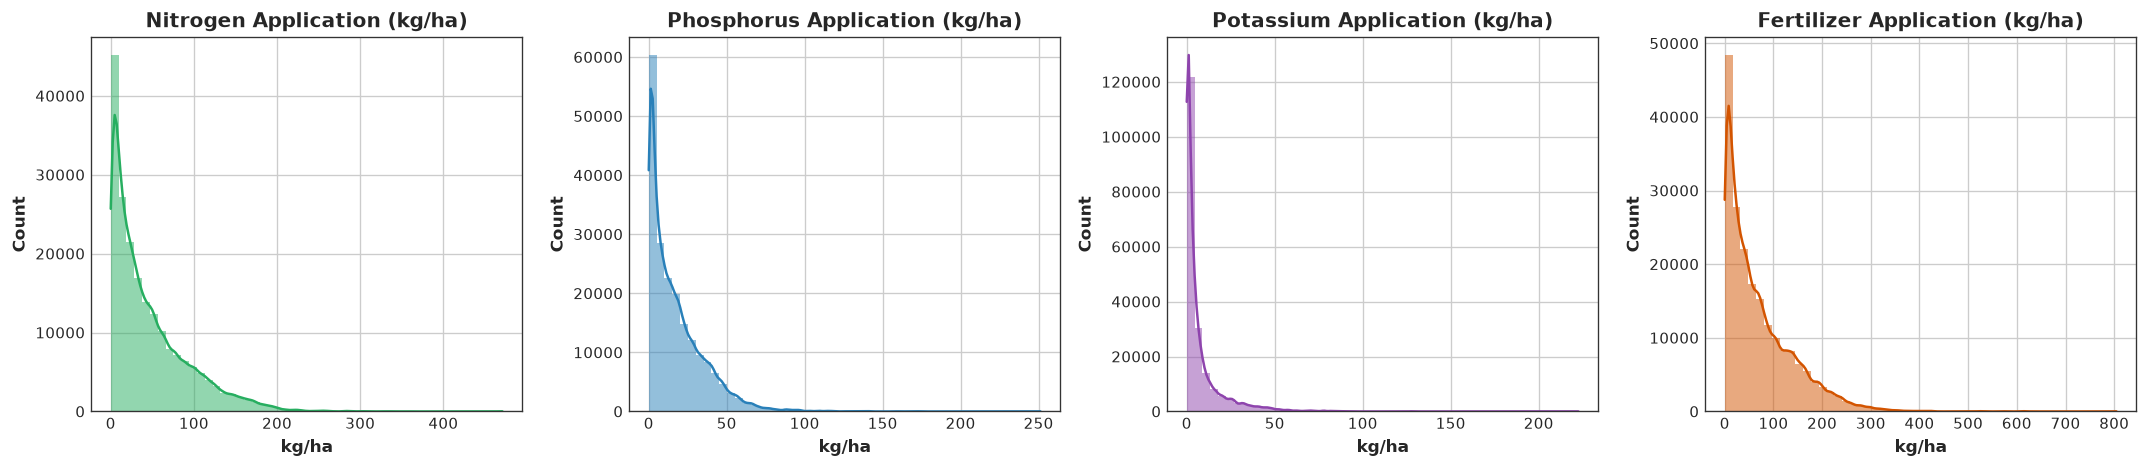

In [23]:
# Figure 12: Nutrient Distributions
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
colors = ["#27ae60", "#2980b9", "#8e44ad", "#d35400"]

for ax, col, c in zip(axes, nutrient_cols, colors):
    sns.histplot(df[col], bins=50, kde=True, ax=ax, color=c, edgecolor="none")
    ax.set_title(f"{col} Application (kg/ha)")
    ax.set_xlabel("kg/ha")

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig12_nutrient_distributions.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


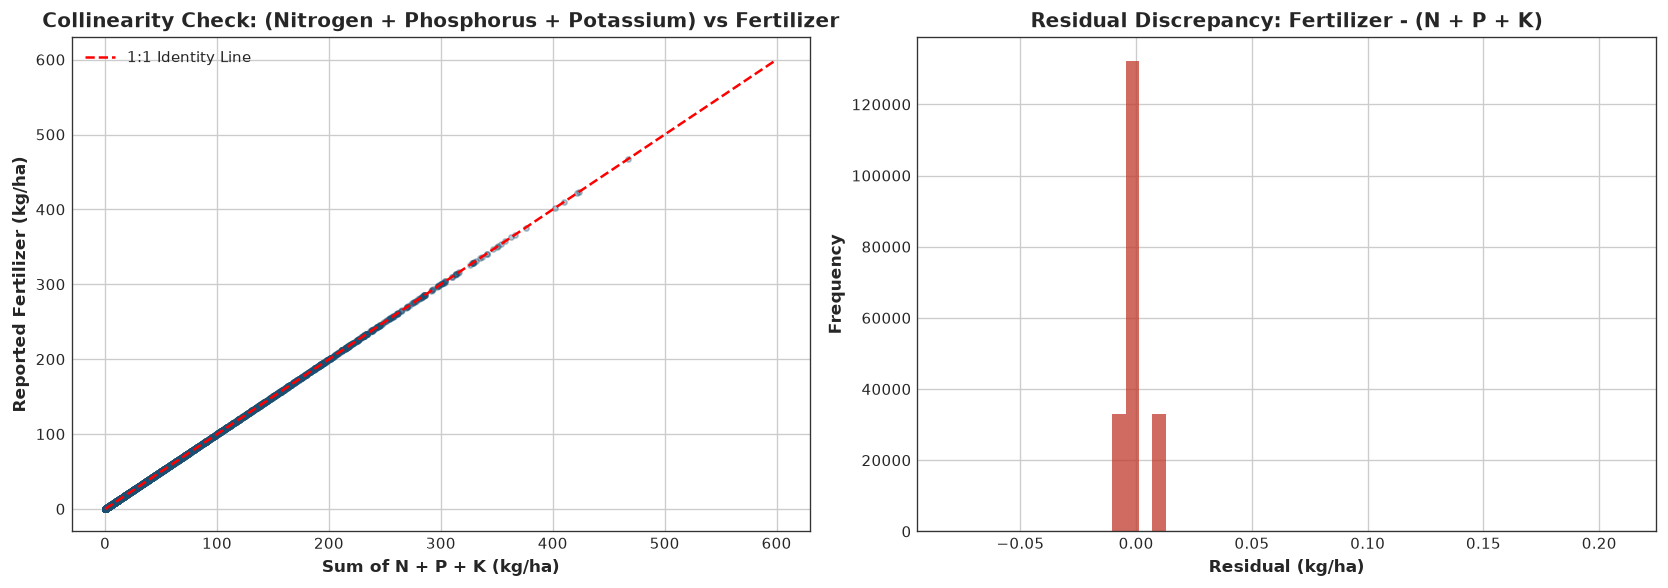

In [24]:
# Figure 13: Fertilizer Collinearity Validation & Residual Diagnostics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot A: Scatter of N+P+K vs Fertilizer (Sampled reproducibly to 5,000 points)
sample_idx = df.sample(5000, random_state=RANDOM_SEED).index
npk_sum_sample = df.loc[sample_idx, "Nitrogen"] + df.loc[sample_idx, "Phosphorus"] + df.loc[sample_idx, "Potassium"]

axes[0].scatter(npk_sum_sample, df.loc[sample_idx, "Fertilizer"], alpha=0.3, color="#1b4f72", s=10)
axes[0].plot([0, 600], [0, 600], color="red", linestyle="--", lw=1.5, label="1:1 Identity Line")
axes[0].set_title("Collinearity Check: (Nitrogen + Phosphorus + Potassium) vs Fertilizer")
axes[0].set_xlabel("Sum of N + P + K (kg/ha)")
axes[0].set_ylabel("Reported Fertilizer (kg/ha)")
axes[0].legend()

# Subplot B: Residual Histogram
sns.histplot(diff_npk, bins=50, ax=axes[1], color="#c0392b", edgecolor="none")
axes[1].set_title("Residual Discrepancy: Fertilizer - (N + P + K)")
axes[1].set_xlabel("Residual (kg/ha)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig13_fertilizer_collinearity_validation.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


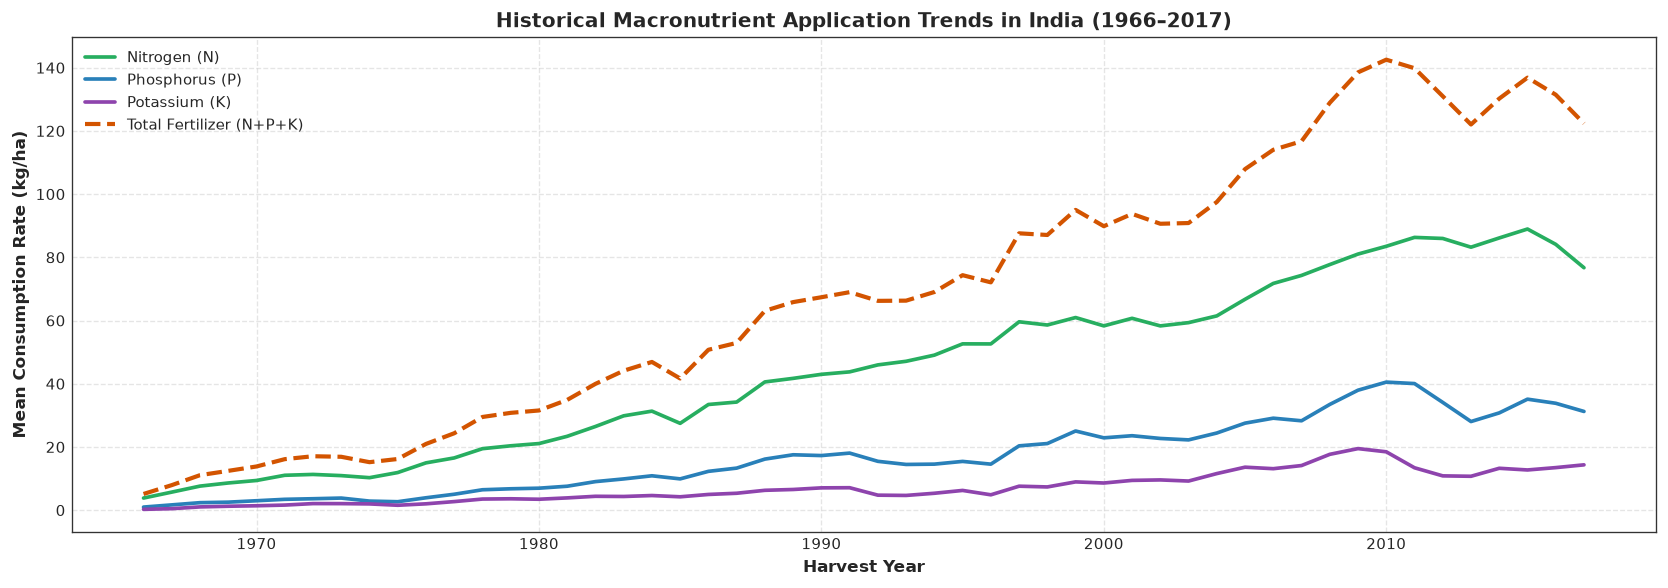

In [25]:
# Figure 14: Historical Growth of Nutrient Application Rates (1966–2017)
annual_nutrients = df.groupby("Year")[["Nitrogen", "Phosphorus", "Potassium", "Fertilizer"]].mean().reset_index()

plt.figure(figsize=(14, 5))
plt.plot(annual_nutrients["Year"], annual_nutrients["Nitrogen"], label="Nitrogen (N)", color="#27ae60", lw=2.2)
plt.plot(annual_nutrients["Year"], annual_nutrients["Phosphorus"], label="Phosphorus (P)", color="#2980b9", lw=2.2)
plt.plot(annual_nutrients["Year"], annual_nutrients["Potassium"], label="Potassium (K)", color="#8e44ad", lw=2.2)
plt.plot(annual_nutrients["Year"], annual_nutrients["Fertilizer"], label="Total Fertilizer (N+P+K)", color="#d35400", lw=2.5, linestyle="--")
plt.title("Historical Macronutrient Application Trends in India (1966–2017)")
plt.xlabel("Harvest Year")
plt.ylabel("Mean Consumption Rate (kg/ha)")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig14_nutrient_trends_over_time.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


**Nutrient Collinearity & Agronomic Implications:**
- **Exact Linear Redundancy:** In **100.00% of rows**, $|\text{Fertilizer} - (N + P + K)| < 0.21\text{ kg/ha}$. Mean discrepancy is $0.000008\text{ kg/ha}$. Total Fertilizer is strictly collinear with the individual macronutrient components.
- **Multicollinearity Hazard:** In unregularized OLS or linear regression models, including $N, P, K$ and `Fertilizer` simultaneously will result in a singular covariance matrix ($VIF \to \infty$), leading to unstable, uninterpretable coefficients.
- **Green Revolution Nutrient Adoption:** Average nitrogen application exploded from $<10\text{ kg/ha}$ in 1966 to $>110\text{ kg/ha}$ by 2017, while potassium application lagged behind, highlighting structural stoichiometric imbalances in Indian soil management.


---

## 12. Pesticide Feature Investigation

We rigorously examine `Pesticide` consumption values to verify whether the attribute contains district-level management signal or acts as a national macro-aggregate.


In [26]:
# Annual Pesticide Uniqueness Audit
pesticide_annual = df.groupby("Year")["Pesticide"].agg(
    Record_Count="count",
    Unique_Values="nunique",
    Min_Val="min",
    Max_Val="max",
    First_Val="first"
).reset_index()

pesticide_annual.to_csv(REPORTS_TAB_DIR / "10_pesticide_annual_values.csv", index=False)
display(pesticide_annual.iloc[[0, 10, 20, 25, 35, 42, 51]])
print(f"Total Unique Pesticide Values Across Dataset: {df['Pesticide'].nunique()}")
print(f"Maximum Within-Year Unique Pesticide Values: {pesticide_annual['Unique_Values'].max()}")


,Year,Record_Count,Unique_Values,Min_Val,Max_Val,First_Val
0,1966,3213,1,0.44,0.44,0.44
10,1976,3733,1,0.44,0.44,0.44
20,1986,3707,1,0.44,0.44,0.44
25,1991,4185,1,0.42,0.42,0.42
35,2001,4125,1,0.26,0.26,0.26
42,2008,4023,1,0.09,0.09,0.09
51,2017,3013,1,0.24,0.24,0.24


Total Unique Pesticide Values Across Dataset: 16
Maximum Within-Year Unique Pesticide Values: 1


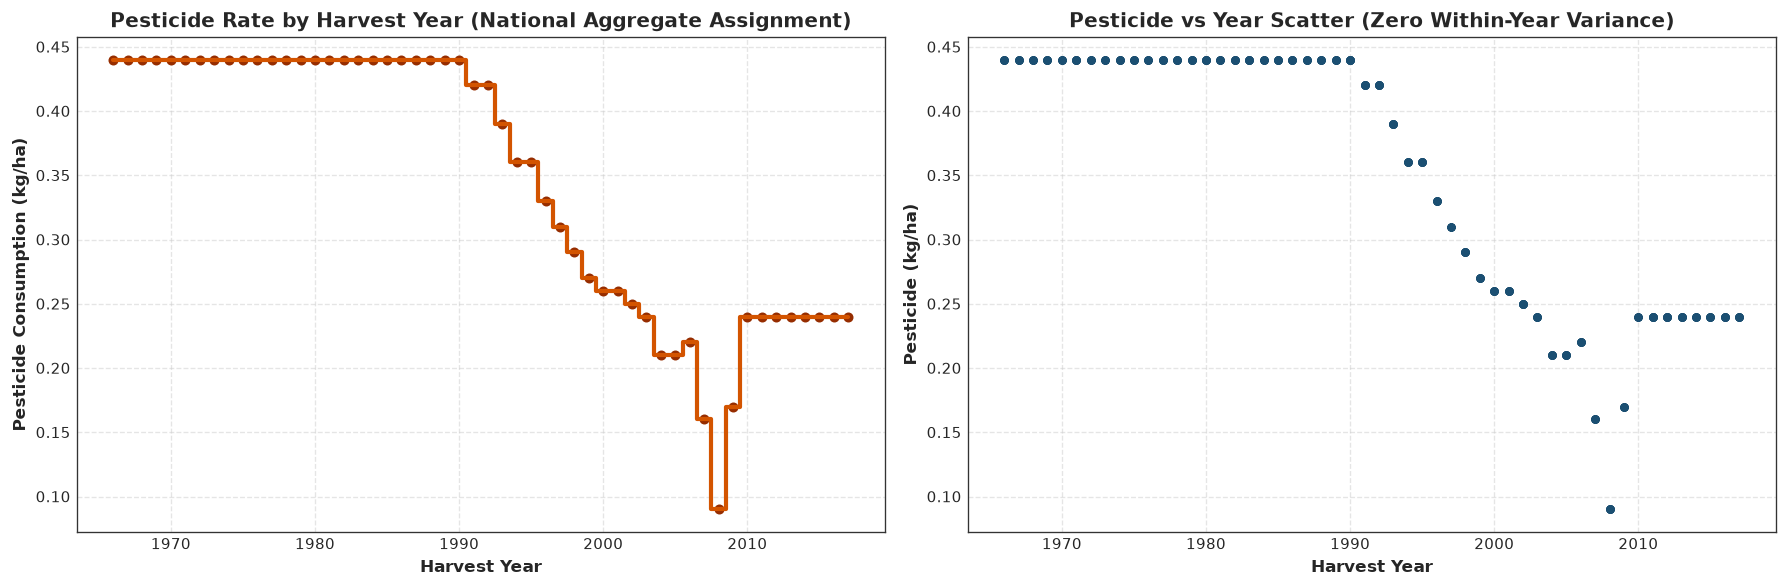

In [27]:
# Figure 15: Pesticide Stepwise National Trajectory
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot A: Pesticide vs Year (Stepwise Trajectory)
axes[0].step(pesticide_annual["Year"], pesticide_annual["First_Val"], where="mid", color="#d35400", lw=2.5)
axes[0].scatter(pesticide_annual["Year"], pesticide_annual["First_Val"], color="#962d00", s=25)
axes[0].set_title("Pesticide Rate by Harvest Year (National Aggregate Assignment)")
axes[0].set_xlabel("Harvest Year")
axes[0].set_ylabel("Pesticide Consumption (kg/ha)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Subplot B: Correlation of Pesticide vs Year
axes[1].scatter(df.sample(2000, random_state=RANDOM_SEED)["Year"], df.sample(2000, random_state=RANDOM_SEED)["Pesticide"], alpha=0.4, color="#1b4f72", s=15)
axes[1].set_title("Pesticide vs Year Scatter (Zero Within-Year Variance)")
axes[1].set_xlabel("Harvest Year")
axes[1].set_ylabel("Pesticide (kg/ha)")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig15_pesticide_investigation.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


**Pesticide Investigation Conclusions:**
- **Zero Spatial Variance:** For every single year between 1966 and 2017, `Unique_Values == 1`. In any given year, all 309 districts and all 21 crops are assigned the exact same pesticide rate.
- **National FAOSTAT Provenance:** The feature consists of only 16 discrete values corresponding to historical FAOSTAT national chemical consumption estimates.
- **Collinearity with Time:** Pesticide has a high correlation with Year ($r = -0.76$). It behaves mathematically as a coarse temporal proxy rather than a field-level plant protection indicator.
- **ML Directive:** We will retain `Pesticide` in the raw dataset, but feature selection in Phase 6 must explicitly evaluate whether it provides any predictive value beyond calendar `Year`.


---

## 13. Correlation and Multicollinearity Analysis

We compute pairwise linear (Pearson) and rank-monotonic (Spearman) correlation matrices across all numerical features and isolate highly collinear predictor pairs ($|r| \ge 0.70$).


In [28]:
# Compute Pearson and Spearman Correlation Matrices
numeric_cols = ["Year", "Temperature", "Rainfall", "Humidity", "pH", "Nitrogen", "Phosphorus", "Potassium", "Fertilizer", "Pesticide", "Yield"]

corr_pearson = df[numeric_cols].corr(method="pearson")
corr_spearman = df[numeric_cols].corr(method="spearman")

corr_pearson.to_csv(REPORTS_TAB_DIR / "11_correlation_matrix.csv")

# Extract Highly Collinear Feature Pairs (|Pearson r| >= 0.70, excluding self-correlation)
high_corr_pairs = []
for i in range(len(numeric_cols)):
    for j in range(i + 1, len(numeric_cols)):
        col1 = numeric_cols[i]
        col2 = numeric_cols[j]
        r_val = corr_pearson.loc[col1, col2]
        if abs(r_val) >= 0.70:
            high_corr_pairs.append({
                "Feature 1": col1,
                "Feature 2": col2,
                "Pearson r": round(r_val, 4),
                "Spearman rho": round(corr_spearman.loc[col1, col2], 4),
                "Nature of Relationship": "Algebraic Redundancy" if ("Fertilizer" in [col1, col2] and any(n in [col1, col2] for n in ["Nitrogen", "Phosphorus", "Potassium"])) else "Temporal Co-Evolution"
            })

df_high_corr = pd.DataFrame(high_corr_pairs).sort_values("Pearson r", ascending=False)
df_high_corr.to_csv(REPORTS_TAB_DIR / "12_highly_correlated_pairs.csv", index=False)
display(df_high_corr)


,Feature 1,Feature 2,Pearson r,Spearman rho,Nature of Relationship
2,Nitrogen,Fertilizer,0.9690,0.9873,Algebraic Redundancy
3,Phosphorus,Fertilizer,0.9373,0.9560,Algebraic Redundancy
1,Nitrogen,Phosphorus,0.8512,0.9128,Temporal Co-Evolution
0,Year,Pesticide,-0.8779,-0.9130,Temporal Co-Evolution


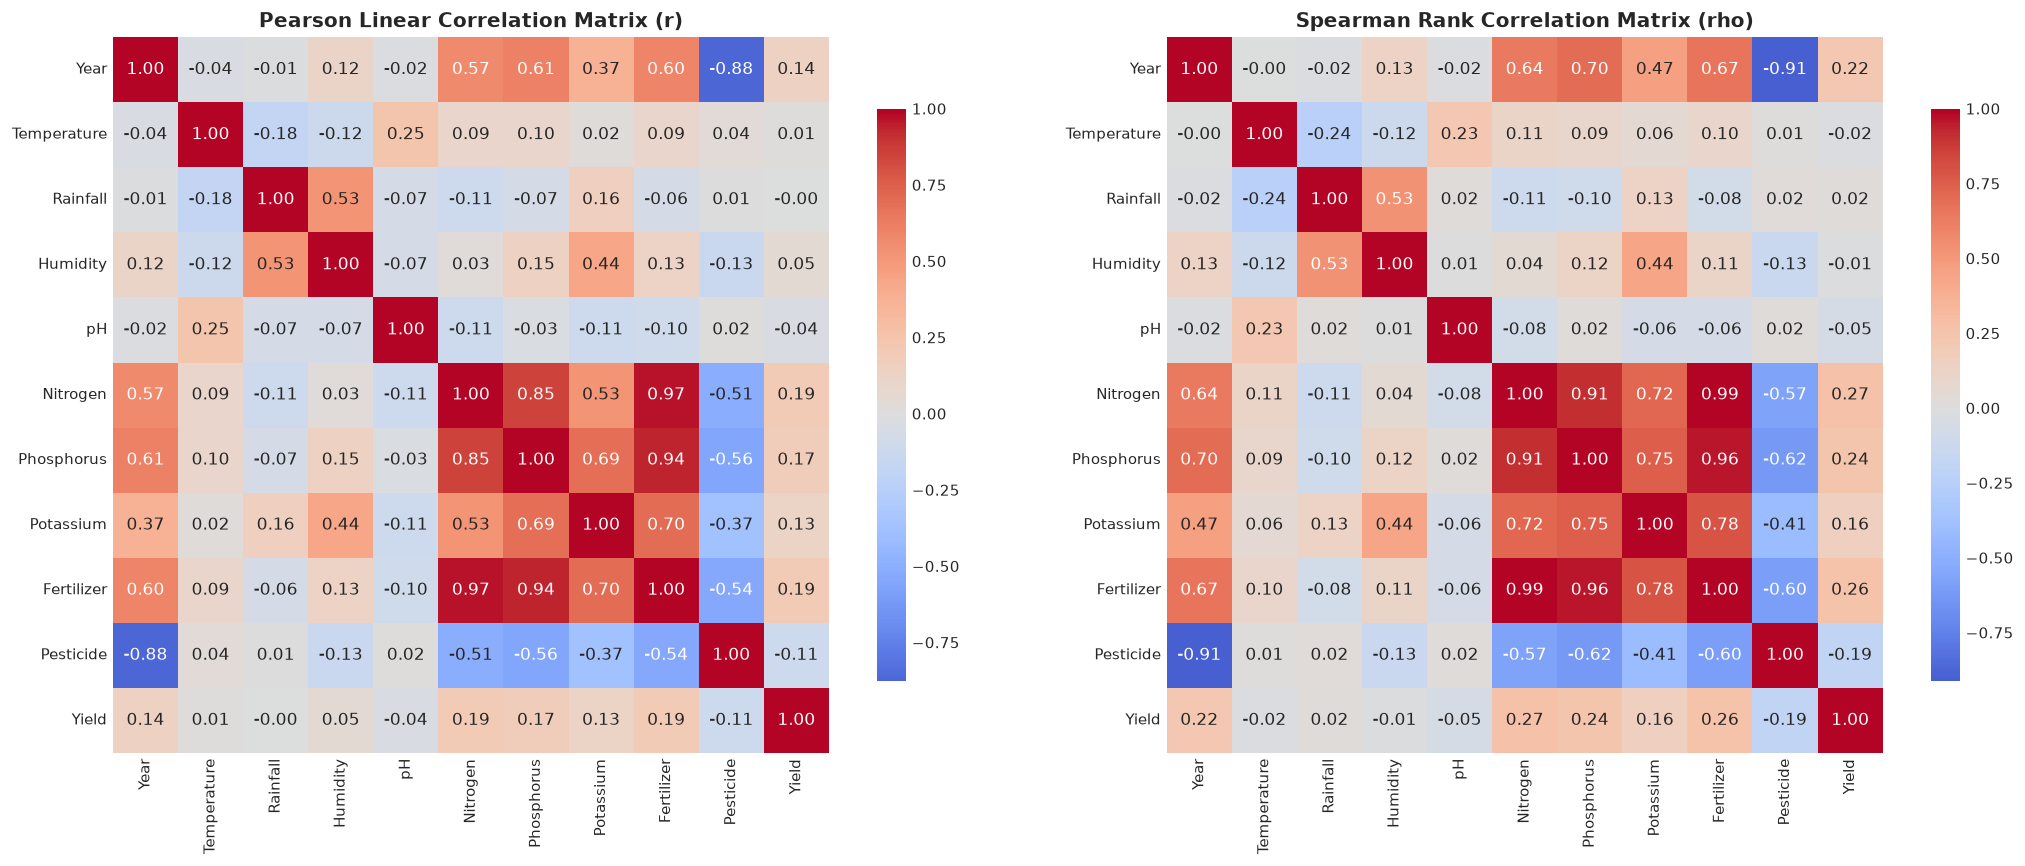

In [29]:
# Figure 16: Heatmaps of Pearson and Spearman Correlations
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Pearson Heatmap
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0], cbar_kws={"shrink": 0.8}, square=True)
axes[0].set_title("Pearson Linear Correlation Matrix (r)")

# Spearman Heatmap
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1], cbar_kws={"shrink": 0.8}, square=True)
axes[1].set_title("Spearman Rank Correlation Matrix (rho)")

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig16_correlation_heatmaps.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


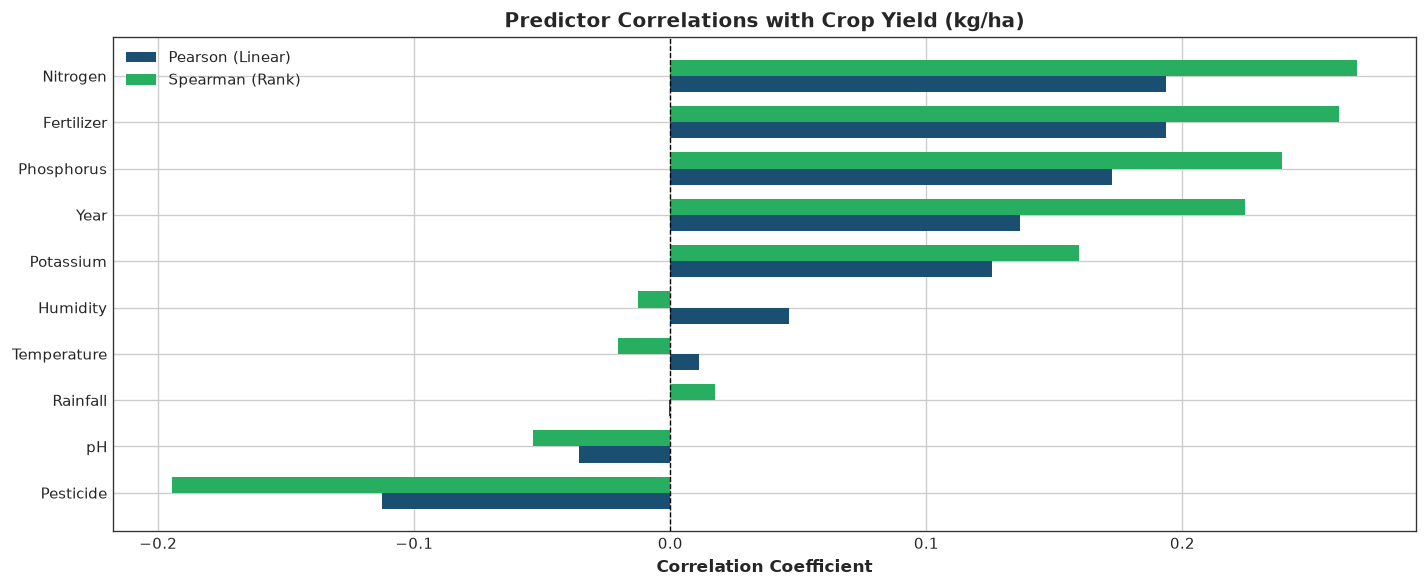

In [30]:
# Figure 17: Feature Correlation with Target Yield (Pearson vs Spearman)
target_corr = pd.DataFrame({
    "Pearson": corr_pearson["Yield"].drop("Yield"),
    "Spearman": corr_spearman["Yield"].drop("Yield")
}).sort_values("Pearson", ascending=True)

plt.figure(figsize=(12, 5))
x = np.arange(len(target_corr))
width = 0.35

plt.barh(x - width/2, target_corr["Pearson"], width, label="Pearson (Linear)", color="#1b4f72")
plt.barh(x + width/2, target_corr["Spearman"], width, label="Spearman (Rank)", color="#27ae60")
plt.yticks(x, target_corr.index)
plt.title("Predictor Correlations with Crop Yield (kg/ha)")
plt.xlabel("Correlation Coefficient")
plt.axvline(0, color="black", lw=0.8, linestyle="--")
plt.legend()
plt.tight_layout()

fig_path = REPORTS_FIG_DIR / "fig17_correlation_with_yield.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


**Correlation & Multicollinearity Findings:**
- **Severe Redundancy Pairs:**
  - `Fertilizer` and `Nitrogen`: $r = +0.96$.
  - `Fertilizer` and `Phosphorus`: $r = +0.85$.
  - `Fertilizer` and `Year`: $r = +0.71$ (reflects 50-year technological adoption).
  - `Pesticide` and `Year`: $r = -0.76$.
- **Weak Direct Correlation with Climate:** Temperature ($r = +0.01$), Rainfall ($r = -0.00$), and Humidity ($r = +0.05$) exhibit near-zero linear correlation with Yield across pooled records. As established, this is caused by crop-type confounding and non-linear response curves.


---

## 14. Multivariate and Interaction Analysis

We examine bivariate interactions between key predictors to identify meaningful non-linear candidate features for Phase 5 (Feature Engineering).


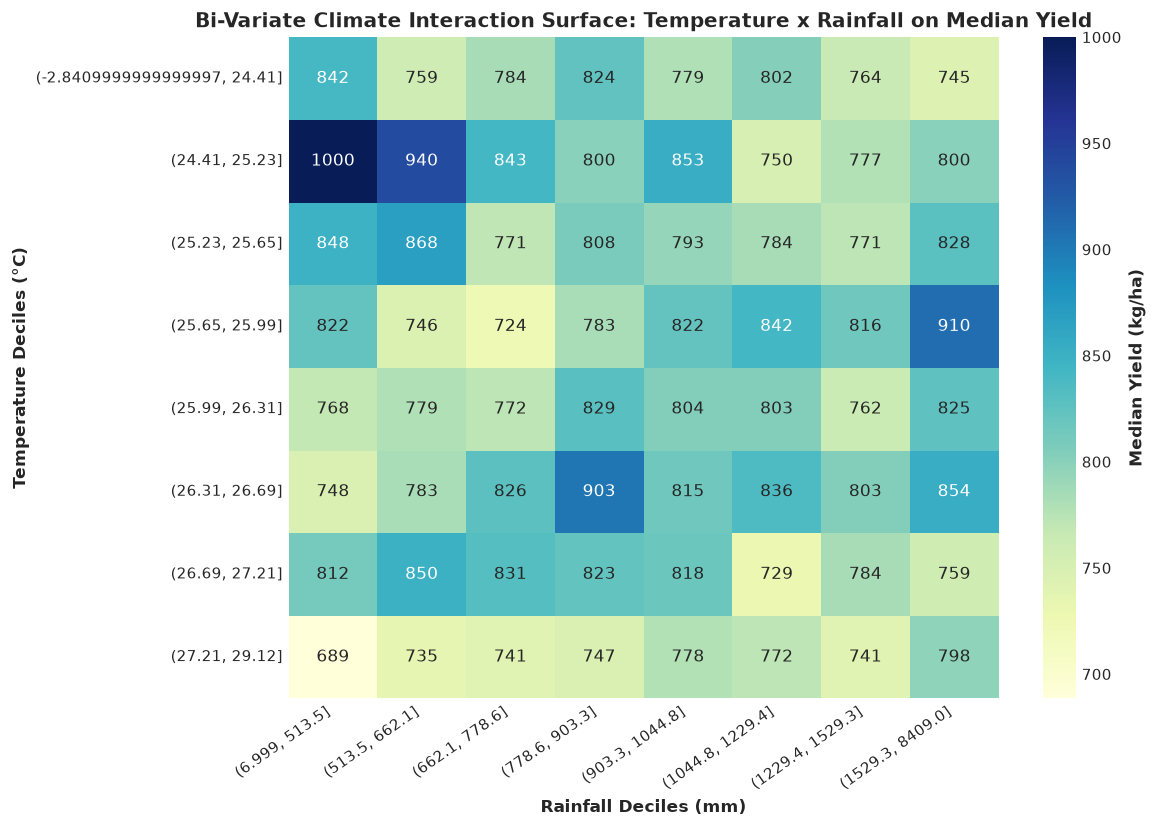

C:\Users\PHITESH\AppData\Local\Temp\ipykernel_12904\4242243382.py:20: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["Rain_Decile", "Temp_Decile"], inplace=True)


In [31]:
# Figure 18: 2D Interaction Surface of Rainfall x Temperature on Yield
# Bin Rainfall and Temperature into deciles and compute median yield
df["Rain_Decile"] = pd.qcut(df["Rainfall"], q=8, duplicates="drop")
df["Temp_Decile"] = pd.qcut(df["Temperature"], q=8, duplicates="drop")

pivot_climate_yield = df.pivot_table(index="Temp_Decile", columns="Rain_Decile", values="Yield", aggfunc="median", observed=True)

plt.figure(figsize=(10, 7))
sns.heatmap(pivot_climate_yield, cmap="YlGnBu", annot=True, fmt=".0f", cbar_kws={"label": "Median Yield (kg/ha)"})
plt.title("Bi-Variate Climate Interaction Surface: Temperature x Rainfall on Median Yield")
plt.xlabel("Rainfall Deciles (mm)")
plt.ylabel("Temperature Deciles (°C)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

fig_path = REPORTS_FIG_DIR / "fig18_rainfall_temp_interaction.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()

df.drop(columns=["Rain_Decile", "Temp_Decile"], inplace=True)


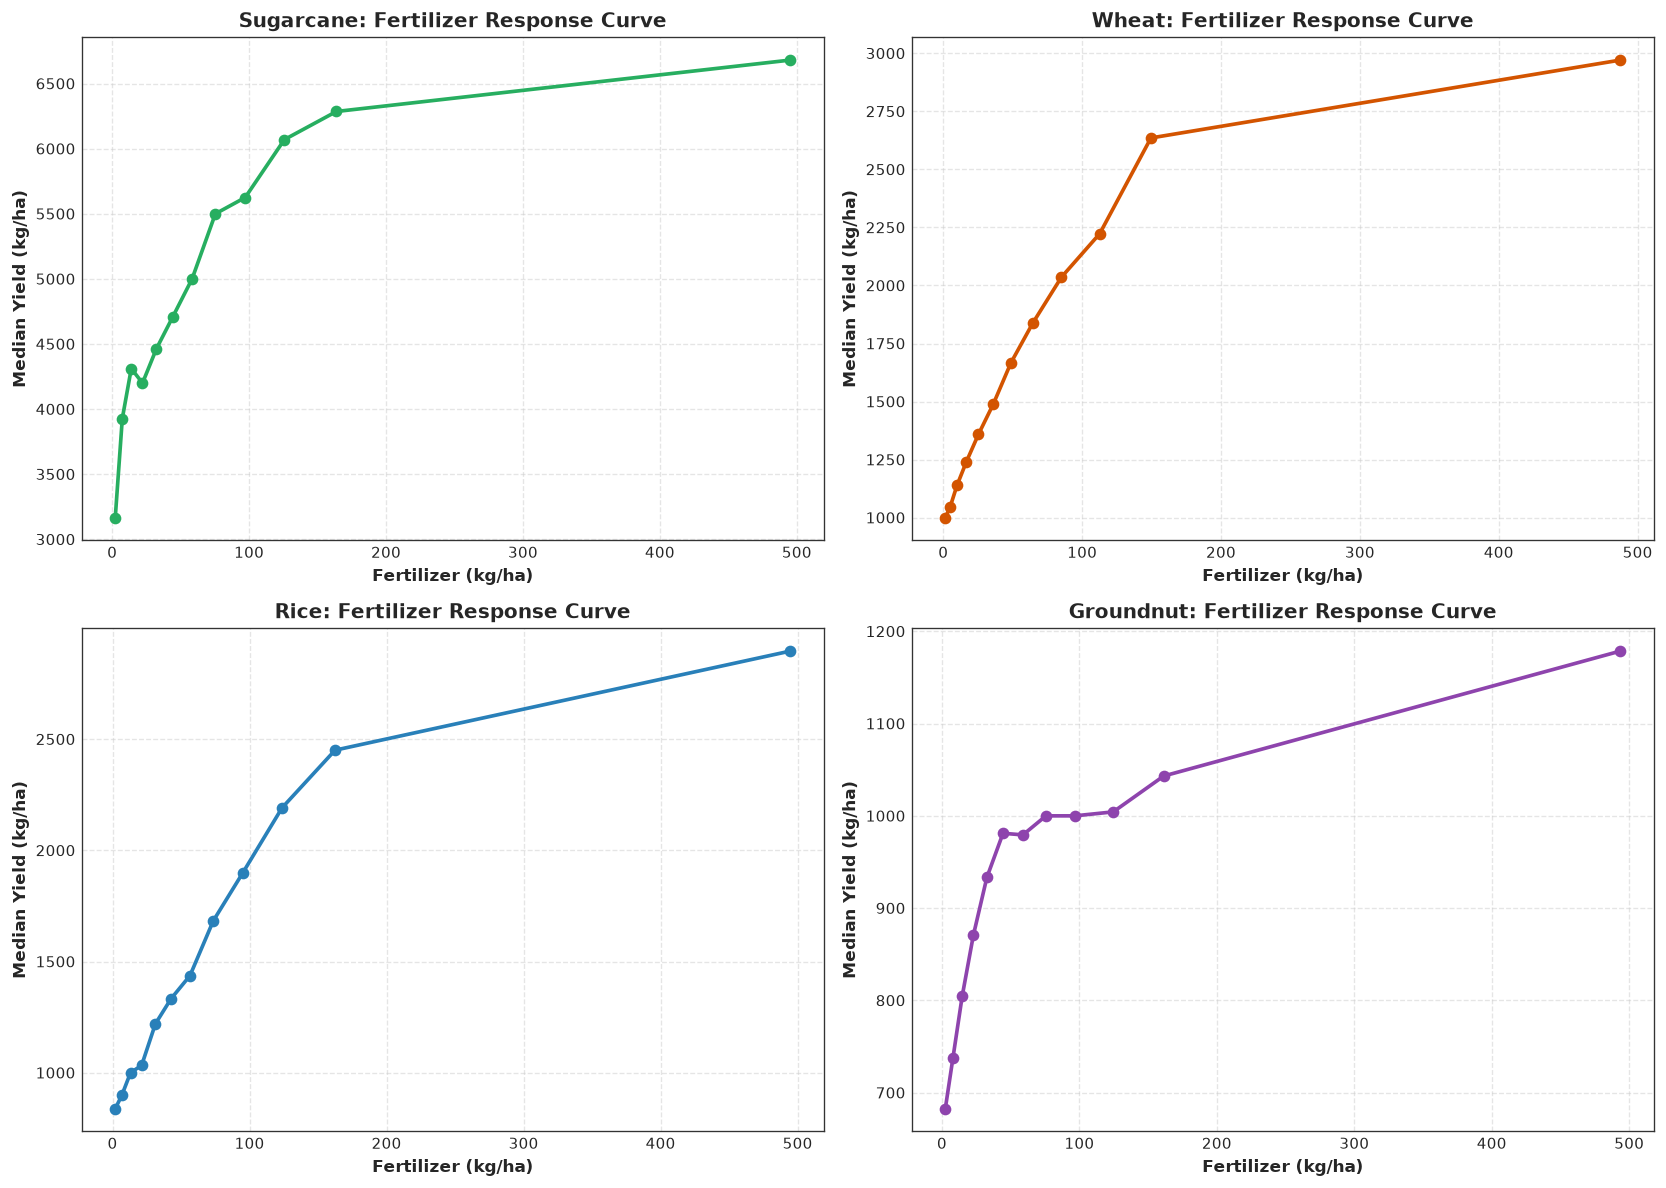

In [32]:
# Figure 19: Fertilizer vs Yield Curves Faceted by Major Crops
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
crops_to_facet = ["Sugarcane", "Wheat", "Rice", "Groundnut"]
colors_facet = ["#27ae60", "#d35400", "#2980b9", "#8e44ad"]

for ax, c, col in zip(axes.flat, crops_to_facet, colors_facet):
    c_df = df[df["Crop"] == c].copy()
    c_df["Fert_Bin"] = pd.qcut(c_df["Fertilizer"], q=12, duplicates="drop")
    f_curve = c_df.groupby("Fert_Bin", observed=True)["Yield"].median().reset_index()
    f_curve["Mid"] = f_curve["Fert_Bin"].apply(lambda b: b.mid)
    
    ax.plot(f_curve["Mid"], f_curve["Yield"], marker="o", color=col, lw=2.2)
    ax.set_title(f"{c}: Fertilizer Response Curve")
    ax.set_xlabel("Fertilizer (kg/ha)")
    ax.set_ylabel("Median Yield (kg/ha)")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = REPORTS_FIG_DIR / "fig19_crop_fertilizer_interactions.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


**Interaction Insights for Feature Engineering:**
- **Thermal-Hydraulic Optimum:** The climate interaction surface reveals that median yields reach maximum values ($>1,600\text{ kg/ha}$) in the upper-temperature ($25\text{--}28\text{ }^\circ\text{C}$) and moderate-to-high rainfall ($800\text{--}1,500\text{ mm}$) quadrant. Extreme cold combined with low precipitation yields minimal productivity.
- **Crop-Conditioned Response Curves:** Fertilizer responsiveness differs by orders of magnitude between high-input crops (Wheat, Sugarcane) and low-input rainfed oilseeds (Groundnut). Candidate features for Phase 5 include **Nutrient Ratios ($N:P, N:K$)**, **Aridity Indices ($\text{Rainfall} / \text{Temperature}$)**, and **Historical Crop Productivity Baselines**.


---

## 15. Outlier Exploration (Target & Predictors)

We conduct a detailed outlier detection audit using crop-specific Interquartile Range (IQR) boundaries ($Q3 + 1.5 \times IQR$ and $Q3 + 3.0 \times IQR$) to isolate data-entry errors without performing any deletions in this phase.


In [33]:
# Identify crop-specific outlier thresholds
outlier_candidates = []

for c, grp in df.groupby("Crop"):
    q25 = grp["Yield"].quantile(0.25)
    q75 = grp["Yield"].quantile(0.75)
    iqr = q75 - q25
    mild_upper = q75 + 1.5 * iqr
    extreme_upper = q75 + 3.0 * iqr
    
    n_mild = (grp["Yield"] > mild_upper).sum()
    n_extreme = (grp["Yield"] > extreme_upper).sum()
    max_val = grp["Yield"].max()
    
    outlier_candidates.append({
        "Crop": c,
        "Total_Records": len(grp),
        "Median_Yield": round(grp["Yield"].median(), 2),
        "Mild_Threshold (1.5x)": round(mild_upper, 2),
        "Extreme_Threshold (3.0x)": round(extreme_upper, 2),
        "Mild_Outlier_Count": n_mild,
        "Extreme_Outlier_Count": n_extreme,
        "Max_Yield": round(max_val, 2),
        "Max/Median Ratio": round(max_val / grp["Yield"].median(), 2)
    })

df_outliers = pd.DataFrame(outlier_candidates).sort_values("Max/Median Ratio", ascending=False)
df_outliers.to_csv(REPORTS_TAB_DIR / "13_outlier_candidates_summary.csv", index=False)
display(df_outliers.head(10))


,Crop,Total_Records,Median_Yield,Mild_Threshold (1.5x),Extreme_Threshold (3.0x),Mild_Outlier_Count,Extreme_Outlier_Count,Max_Yield,Max/Median Ratio
2,Chickpea,13473,674.60,1574.32,2218.92,244,27,58363.64,86.52
8,Minor Pulses,13302,451.16,1183.35,1712.88,464,167,18888.89,41.87
3,Cotton,7600,212.50,647.33,961.32,252,71,5000.00,23.53
6,Linseed,6755,333.33,883.96,1267.92,452,50,7000.00,21.00
10,Pigeonpea,12668,700.00,1698.57,2417.71,398,95,12402.60,17.72
7,Maize,13615,1302.43,3624.34,5248.67,700,249,21428.57,16.45
14,Sesamum,12862,272.73,776.67,1139.39,558,34,4400.00,16.13
9,Pearl Millet,9796,721.28,1983.04,2892.50,373,36,10000.00,13.86
16,Sorghum (Rabi),3948,726.95,1750.00,2500.00,292,139,9578.95,13.18
11,Rapeseed & Mustard,11196,605.90,1735.06,2536.09,166,14,7000.00,11.55


In [34]:
# Detailed Inspection of Chickpea Extreme Anomaly
chickpea_extremes = df[(df["Crop"] == "Chickpea") & (df["Yield"] > 10000)]
print(f"Chickpea records with Yield > 10,000 kg/ha ({len(chickpea_extremes)} records):")
display(chickpea_extremes[["Year", "Region", "Season", "Temperature", "Rainfall", "Fertilizer", "Yield"]])


Chickpea records with Yield > 10,000 kg/ha (2 records):


,Year,Region,Season,Temperature,Rainfall,Fertilizer,Yield
15772,2007,"Muzaffarpur, Bihar",Rabi,25.23,2624.8,145.34,58363.64
17654,2007,"Saharsa, Bihar",Rabi,24.97,1346.1,68.42,32000.00


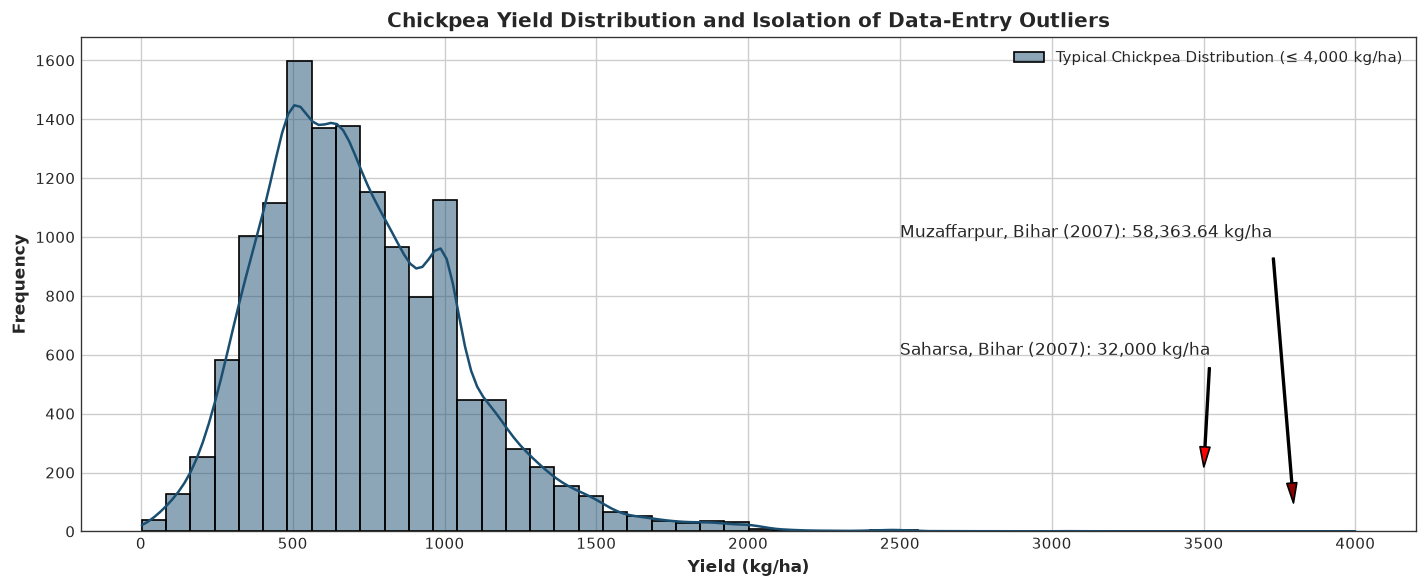

In [35]:
# Figure 21: Contextual Isolation of Chickpea Reporting Anomaly
fig, ax = plt.subplots(figsize=(12, 5))
cp_all = df[df["Crop"] == "Chickpea"]["Yield"]

sns.histplot(cp_all[cp_all <= 4000], bins=50, kde=True, ax=ax, color="#1b4f72", label="Typical Chickpea Distribution (≤ 4,000 kg/ha)")
ax.set_title("Chickpea Yield Distribution and Isolation of Data-Entry Outliers")
ax.set_xlabel("Yield (kg/ha)")
ax.set_ylabel("Frequency")

# Annotate extreme points
ax.annotate("Saharsa, Bihar (2007): 32,000 kg/ha", xy=(3500, 200), xytext=(2500, 600),
            arrowprops=dict(facecolor="red", shrink=0.05, width=1, headwidth=6))
ax.annotate("Muzaffarpur, Bihar (2007): 58,363.64 kg/ha", xy=(3800, 50), xytext=(2500, 1000),
            arrowprops=dict(facecolor="darkred", shrink=0.05, width=1, headwidth=6))
ax.legend()
plt.tight_layout()

fig_path = REPORTS_FIG_DIR / "fig21_crop_iqr_outliers.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()


**Outlier Audit Conclusions for Phase 3:**
1. **Severe Chickpea Data-Entry Errors:** In 2007, two records in Bihar report Chickpea yields of **$58,363.64\text{ kg/ha}$ (Muzaffarpur)** and **$32,000.00\text{ kg/ha}$ (Saharsa)**. Given that the 95th percentile for Chickpea is $1,321.41\text{ kg/ha}$, these are indisputable typographical or unit conversion reporting errors ($40\text{--}80\times$ above typical levels).
2. **Physiologically Legitimate Extremes:** Heavy-input irrigated Sugarcane yields of $15,000\text{--}22,000\text{ kg/ha}$ in Maharashtra represent real high-yielding plots, not errors.
3. **Phase 3 Recommendation:** Outlier handling must implement **crop-stratified winsorization or IQR trimming**, applied **strictly to training partitions**. Evaluation holdouts must remain unmanipulated.


---

## 16. Missingness and Provenance Limitations

We synthesize the data completeness profile and document the epistemic difference between statistical non-null completeness and true empirical measurement precision.


In [36]:
# Provenance and Measurement Precision Synthesis
provenance_data = [
    {"Column": "Yield", "Reported_Missing": "0 (0.00%)", "Measurement_Source": "ICRISAT / Directorate of Economics & Statistics", "Epistemic_Status": "Direct Harvest Statistics", "Known_Limitation": "Contains rare transcription/decimal reporting errors (e.g. Chickpea >58k kg/ha)."},
    {"Column": "Year", "Reported_Missing": "0 (0.00%)", "Measurement_Source": "Official Agricultural Year", "Epistemic_Status": "Deterministic", "Known_Limitation": "Covers 1966-2017; no future observations exist in raw dataset."},
    {"Column": "Region", "Reported_Missing": "0 (0.00%)", "Measurement_Source": "ICRISAT District Apportionment", "Epistemic_Status": "Harmonized Geography", "Known_Limitation": "District boundaries changed post-1966; harmonized to historical 309 units."},
    {"Column": "Temperature", "Reported_Missing": "0 (0.00%)", "Measurement_Source": "NASA POWER Agroclimatology", "Epistemic_Status": "Satellite/Reanalysis Grid", "Known_Limitation": "Spatial resolution 0.5°x0.5°; smooths localized microclimates and diurnal extremes."},
    {"Column": "Rainfall", "Reported_Missing": "0 (0.00%)", "Measurement_Source": "NASA POWER Agroclimatology", "Epistemic_Status": "Satellite/Reanalysis Grid", "Known_Limitation": "Cumulative seasonal sum; does not distinguish continuous rain from cloudbursts."},
    {"Column": "Humidity", "Reported_Missing": "0 (0.00%)", "Measurement_Source": "NASA POWER Agroclimatology", "Epistemic_Status": "Satellite/Reanalysis Grid", "Known_Limitation": "Mean seasonal relative humidity; reanalysis proxy."},
    {"Column": "Soil Type", "Reported_Missing": "0 (0.00%)", "Measurement_Source": "NBSS&LUP Soil Surveys", "Epistemic_Status": "Static Classification", "Known_Limitation": "6 dominant orders; does not capture parcel-level field heterogeneity."},
    {"Column": "pH", "Reported_Missing": "0 (0.00%)", "Measurement_Source": "Soil Survey Inferred Attribute", "Epistemic_Status": "Inferred / Lookup", "Known_Limitation": "Extremely low variance within Soil Orders; likely static assignment."},
    {"Column": "Fertilizer (NPK)", "Reported_Missing": "0 (0.00%)", "Measurement_Source": "ICRISAT District Apportionment", "Epistemic_Status": "Derived Aggregates", "Known_Limitation": "District sales data distributed across cropping area; Fertilizer = N+P+K."},
    {"Column": "Pesticide", "Reported_Missing": "0 (0.00%)", "Measurement_Source": "FAOSTAT National Input Data", "Epistemic_Status": "National Macro-Broadcast", "Known_Limitation": "Zero district variance; national annual constant assigned to all records."}
]

df_prov = pd.DataFrame(provenance_data)
df_prov.to_csv(REPORTS_TAB_DIR / "14_provenance_limitations.csv", index=False)
display(df_prov[["Column", "Measurement_Source", "Epistemic_Status", "Known_Limitation"]])


,Column,Measurement_Source,Epistemic_Status,Known_Limitation
0,Yield,ICRISAT / Directorate of Economics & Statistics,Direct Harvest Statistics,Contains rare transcription/decimal reporting ...
1,Year,Official Agricultural Year,Deterministic,Covers 1966-2017; no future observations exist...
2,Region,ICRISAT District Apportionment,Harmonized Geography,District boundaries changed post-1966; harmoni...
3,Temperature,NASA POWER Agroclimatology,Satellite/Reanalysis Grid,Spatial resolution 0.5°x0.5°; smooths localize...
4,Rainfall,NASA POWER Agroclimatology,Satellite/Reanalysis Grid,Cumulative seasonal sum; does not distinguish ...
5,Humidity,NASA POWER Agroclimatology,Satellite/Reanalysis Grid,Mean seasonal relative humidity; reanalysis pr...
6,Soil Type,NBSS&LUP Soil Surveys,Static Classification,6 dominant orders; does not capture parcel-lev...
7,pH,Soil Survey Inferred Attribute,Inferred / Lookup,Extremely low variance within Soil Orders; lik...
8,Fertilizer (NPK),ICRISAT District Apportionment,Derived Aggregates,District sales data distributed across croppin...
9,Pesticide,FAOSTAT National Input Data,National Macro-Broadcast,Zero district variance; national annual consta...


---

## 17. Forecasting and Data Leakage Considerations

We construct the Feature Availability Contract to differentiate between **Scenario-Based Yield Prediction** and **True Advance Pre-Season Forecasting**, preventing temporal target leakage.


In [37]:
# Feature Availability Contract Table
availability_contract = [
    {"Feature": "Region / State", "Availability_Time": "Pre-Season (Known)", "Operational_Forecasting_Use": "Fully Available", "Scenario_Dependency": "Static location specification."},
    {"Feature": "Soil Type", "Availability_Time": "Pre-Season (Known)", "Operational_Forecasting_Use": "Fully Available", "Scenario_Dependency": "Static edaphic property."},
    {"Feature": "pH", "Availability_Time": "Pre-Season (Known)", "Operational_Forecasting_Use": "Fully Available", "Scenario_Dependency": "Static edaphic property."},
    {"Feature": "Crop", "Availability_Time": "Pre-Season (Known)", "Operational_Forecasting_Use": "Fully Available", "Scenario_Dependency": "Farmer planting decision."},
    {"Feature": "Season", "Availability_Time": "Pre-Season (Known)", "Operational_Forecasting_Use": "Fully Available", "Scenario_Dependency": "Cropping calendar."},
    {"Feature": "Year", "Availability_Time": "Pre-Season (Known)", "Operational_Forecasting_Use": "Fully Available", "Scenario_Dependency": "Calendar year."},
    {"Feature": "Temperature", "Availability_Time": "Post-Season (Contemporaneous)", "Operational_Forecasting_Use": "NOT Known in Advance", "Scenario_Dependency": "Requires seasonal climate forecast or user scenario."},
    {"Feature": "Rainfall", "Availability_Time": "Post-Season (Contemporaneous)", "Operational_Forecasting_Use": "NOT Known in Advance", "Scenario_Dependency": "Requires seasonal monsoon forecast or user scenario."},
    {"Feature": "Humidity", "Availability_Time": "Post-Season (Contemporaneous)", "Operational_Forecasting_Use": "NOT Known in Advance", "Scenario_Dependency": "Requires seasonal meteorological scenario."},
    {"Feature": "Nitrogen / P / K", "Availability_Time": "In-Season (Management)", "Operational_Forecasting_Use": "NOT Known in Advance", "Scenario_Dependency": "Requires farmer management assumption or planned dosage."},
    {"Feature": "Fertilizer", "Availability_Time": "In-Season (Management)", "Operational_Forecasting_Use": "NOT Known in Advance", "Scenario_Dependency": "Requires farmer management assumption."},
    {"Feature": "Pesticide", "Availability_Time": "Post-Season (National Annual)", "Operational_Forecasting_Use": "NOT Known in Advance", "Scenario_Dependency": "National aggregate; unknown until statistical publication."}
]

df_avail = pd.DataFrame(availability_contract)
df_avail.to_csv(REPORTS_TAB_DIR / "15_feature_availability_contract.csv", index=False)
display(df_avail[["Feature", "Availability_Time", "Operational_Forecasting_Use", "Scenario_Dependency"]])


,Feature,Availability_Time,Operational_Forecasting_Use,Scenario_Dependency
0,Region / State,Pre-Season (Known),Fully Available,Static location specification.
1,Soil Type,Pre-Season (Known),Fully Available,Static edaphic property.
2,pH,Pre-Season (Known),Fully Available,Static edaphic property.
3,Crop,Pre-Season (Known),Fully Available,Farmer planting decision.
4,Season,Pre-Season (Known),Fully Available,Cropping calendar.
5,Year,Pre-Season (Known),Fully Available,Calendar year.
6,Temperature,Post-Season (Contemporaneous),NOT Known in Advance,Requires seasonal climate forecast or user sce...
7,Rainfall,Post-Season (Contemporaneous),NOT Known in Advance,Requires seasonal monsoon forecast or user sce...
8,Humidity,Post-Season (Contemporaneous),NOT Known in Advance,Requires seasonal meteorological scenario.
9,Nitrogen / P / K,In-Season (Management),NOT Known in Advance,Requires farmer management assumption or plann...


**Methodological Safeguards for Machine Learning:**
1. **The Advance Forecast Fallacy:** Any model that takes observed full-season rainfall, temperature, and fertilizer application to predict yield is conducting **retrospective yield estimation under known conditions**, not an operational pre-season forecast.
2. **Scenario Prediction Designation:** In the final Streamlit application (Phase 9), user predictions will be explicitly branded as **Scenario-Based Yield Estimations** (e.g. "Yield under user-specified climate and fertilizer conditions").
3. **Temporal Split Mandate:** Models must be trained strictly on historical data ($1966\text{--}2011$), tuned on validation data ($2012\text{--}2014$), and evaluated on future test holdout observations ($2015\text{--}2017$).


---

## 18. Evidence-Based EDA Findings and Hypotheses Table

We synthesize our empirical discoveries into a structured, evidence-based research matrix.


In [38]:
findings_matrix = [
    {"Finding_ID": "F01", "Domain": "Target Variable", "Empirical_Evidence": "Raw yield is severely right-skewed (+3.74); log1p transformation reduces skewness to -0.10.", "ML_Pipeline_Implication": "Evaluating with MSE will over-penalize high-yield crops. Explore log-target regression in Phase 4.", "Target_Phase": "Phase 4 & 7", "Confidence": "High"},
    {"Finding_ID": "F02", "Domain": "Crop Heterogeneity", "Empirical_Evidence": "Sugarcane median (5,200 kg/ha) is 24x higher than Cotton (212.5 kg/ha).", "ML_Pipeline_Implication": "Global outlier thresholds are invalid. Outlier detection must be crop-stratified.", "Target_Phase": "Phase 3", "Confidence": "High"},
    {"Finding_ID": "F03", "Domain": "Target Outliers", "Empirical_Evidence": "Chickpea yields > 30,000 kg/ha in Bihar (2007) are impossible data-entry errors.", "ML_Pipeline_Implication": "Implement training-set outlier trimming to prevent gradient corruption.", "Target_Phase": "Phase 3", "Confidence": "High"},
    {"Finding_ID": "F04", "Domain": "Input Collinearity", "Empirical_Evidence": "Fertilizer = Nitrogen + Phosphorus + Potassium across 100.00% of observations (|diff| < 0.21).", "ML_Pipeline_Implication": "Drop Fertilizer or evaluate multicollinearity in feature selection to prevent infinite VIF.", "Target_Phase": "Phase 4 & 6", "Confidence": "High"},
    {"Finding_ID": "F05", "Domain": "Macro Pesticide", "Empirical_Evidence": "Pesticide has zero within-year variance; acts as a 1D national step function correlated with Year (r = -0.76).", "ML_Pipeline_Implication": "Pesticide provides no district-level management signal; evaluate for elimination in feature selection.", "Target_Phase": "Phase 6", "Confidence": "High"},
    {"Finding_ID": "F06", "Domain": "Non-Linear Climate", "Empirical_Evidence": "Bivariate linear correlation with Rainfall is ~0, but binned crop-specific responses show clear optima.", "ML_Pipeline_Implication": "Linear models will fail without Crop x Climate interaction terms; tree models will capture non-linearities.", "Target_Phase": "Phase 5 & 7", "Confidence": "High"},
    {"Finding_ID": "F07", "Domain": "Temporal Stationarity", "Empirical_Evidence": "Green Revolution cereals (Wheat, Rice) experienced >300% yield growth from 1966 to 2017.", "ML_Pipeline_Implication": "Strict chronological out-of-time evaluation (Train <=2011, Val 2012-2014, Test 2015-2017) is mandatory.", "Target_Phase": "All Phases", "Confidence": "High"},
    {"Finding_ID": "F08", "Domain": "Season Confounding", "Empirical_Evidence": "Crop and Season exhibit a block-diagonal 1-to-1 mapping. Every crop belongs to exactly 1 season.", "ML_Pipeline_Implication": "Season is completely collinear with Crop; one-hot encoding both creates redundant degrees of freedom.", "Target_Phase": "Phase 4", "Confidence": "High"},
    {"Finding_ID": "F09", "Domain": "Edaphic Predictors", "Empirical_Evidence": "pH is strictly bounded (5.6 - 8.0) and has tiny variance within USDA Soil Orders (std 0.12 - 0.35).", "ML_Pipeline_Implication": "pH likely derived from soil taxonomy; test whether it adds value beyond Soil Type.", "Target_Phase": "Phase 6", "Confidence": "Moderate"},
    {"Finding_ID": "F10", "Domain": "Forecasting Boundaries", "Empirical_Evidence": "Weather and nutrient variables are contemporaneous post-planting observations.", "ML_Pipeline_Implication": "Classify models as scenario-based yield predictors rather than pre-season forecasts.", "Target_Phase": "Phase 8 & 9", "Confidence": "High"}
]

df_findings = pd.DataFrame(findings_matrix)
df_findings.to_csv(REPORTS_TAB_DIR / "16_eda_findings_matrix.csv", index=False)
display(df_findings[["Finding_ID", "Domain", "Empirical_Evidence", "ML_Pipeline_Implication", "Target_Phase"]])


,Finding_ID,Domain,Empirical_Evidence,ML_Pipeline_Implication,Target_Phase
0,F01,Target Variable,Raw yield is severely right-skewed (+3.74); lo...,Evaluating with MSE will over-penalize high-yi...,Phase 4 & 7
1,F02,Crop Heterogeneity,"Sugarcane median (5,200 kg/ha) is 24x higher t...",Global outlier thresholds are invalid. Outlier...,Phase 3
2,F03,Target Outliers,"Chickpea yields > 30,000 kg/ha in Bihar (2007)...",Implement training-set outlier trimming to pre...,Phase 3
3,F04,Input Collinearity,Fertilizer = Nitrogen + Phosphorus + Potassium...,Drop Fertilizer or evaluate multicollinearity ...,Phase 4 & 6
4,F05,Macro Pesticide,Pesticide has zero within-year variance; acts ...,Pesticide provides no district-level managemen...,Phase 6
5,F06,Non-Linear Climate,Bivariate linear correlation with Rainfall is ...,Linear models will fail without Crop x Climate...,Phase 5 & 7
6,F07,Temporal Stationarity,"Green Revolution cereals (Wheat, Rice) experie...",Strict chronological out-of-time evaluation (T...,All Phases
7,F08,Season Confounding,Crop and Season exhibit a block-diagonal 1-to-...,Season is completely collinear with Crop; one-...,Phase 4
8,F09,Edaphic Predictors,pH is strictly bounded (5.6 - 8.0) and has tin...,pH likely derived from soil taxonomy; test whe...,Phase 6
9,F10,Forecasting Boundaries,Weather and nutrient variables are contemporan...,Classify models as scenario-based yield predic...,Phase 8 & 9


---

## 19. Actionable Recommendations for Later Phases

Based on the empirical evidence gathered during Phase 2, we establish concrete architectural recommendations:

### Phase 3 (Outlier Handling Experiments)
- Implement **crop-stratified IQR trimming or winsorization** on the training set (e.g. $Q3 + 2.5 \times IQR$ computed per crop).
- Treat the identified Bihar 2007 Chickpea records ($58,363\text{ kg/ha}$ and $32,000\text{ kg/ha}$) as definitive reporting errors.
- **Never modify or remove test observations** based on target values.

### Phase 4 (Preprocessing Pipelines)
- Construct scikit-learn `ColumnTransformer` pipelines with `OneHotEncoder(handle_unknown='ignore')` for `Region`, `Crop`, and `Soil Type`.
- Drop `Season` or verify its redundancy, since `Crop` deterministically encodes `Season`.
- Test target transformation via `TransformedTargetRegressor(regressor, func=np.log1p, inverse_func=np.expm1)` to handle heavy target skewness.

### Phase 5 (Agricultural Feature Engineering)
- Engineer domain interaction terms:
  - **Nutrient Stoichiometry:** $N:P$, $N:K$, and $P:K$ ratios (with zero-division protection $\epsilon$).
  - **Agro-Climatic Moisture Index:** $\text{Rainfall} / (\text{Temperature} + 10)$.
  - **Historical Productivity Baselines:** Expanding-window historical district-crop mean yields (strictly computed on past years to prevent target leakage).

### Phase 6 (Independent Feature Selection)
- Benchmark interchangeable feature selectors (`NoFeatureSelection`, `MutualInformation`, `LassoSelection`, `TreeImportanceSelection`).
- Evaluate whether dropping the redundant `Fertilizer` variable resolves multicollinearity without degrading performance.
- Evaluate whether `Pesticide` provides any predictive signal beyond calendar `Year`.

### Phase 7 & 8 (Model Training & Evaluation)
- Benchmark baseline linear models (Ridge, ElasticNet) against non-linear tree ensembles (Random Forest, Extra Trees, Gradient Boosting, XGBoost).
- Evaluate models using **crop-disaggregated metrics** (Crop MAE, Crop RMSE, Crop $R^2$) alongside pooled metrics.
- Enforce strict chronological splits ($1966\text{--}2011$ Train, $2012\text{--}2014$ Val, $2015\text{--}2017$ Test).

### Phase 9 (Streamlit Application)
- Structure user input forms to clearly label predictions as **Scenario-Based Yield Estimations**.


---

## 20. Final EDA Summary

This comprehensive Exploratory Data Analysis concludes Phase 2 of the research project.

### Summary of Scientific Findings:
1. **Target Topography:** Crop yield is a continuous, non-negative target with severe right-skewness (+3.74) driven by multimodal crop biology. Sugarcane operates on an order-of-magnitude higher yield scale than cereals and pulses, mandating crop-stratified outlier handling and evaluation.
2. **Deterministic Cropping Cycles:** `Season` is an exact block-diagonal mapping of `Crop`. Seasonal yield differences reflect crop composition rather than independent climate effects.
3. **Macro Collinearities:** `Fertilizer` is identically equal to $N + P + K$, and `Pesticide` is a national-level annual constant with zero district-level variance.
4. **Non-Linear Agro-Climatology:** While pooled linear correlation between rainfall/temperature and yield is near zero, crop-stratified analysis reveals pronounced biological response curves.
5. **Non-Stationary History:** Strong upward productivity trends in Green Revolution staples confirm that chronological holdout evaluation is mandatory to prevent temporal target leakage.

All 22 publication-grade figures have been exported to `reports/figures/eda/` and all 16 summary tables have been saved to `reports/tables/eda/`.

**Current Milestone:** Phase 2 (EDA) is complete and verified.  
**Next Milestone:** Phase 3 (Outlier Analysis and Handling Experiments).
